# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import ok_k_mer

In [2]:
import importlib
importlib.reload(ok_k_mer)


<module 'ok_k_mer' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer.py'>

In [3]:
import os
# import re
# import multiprocessing as mp
# from random import randint
# from random import sample
# from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [4]:
# import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [5]:
import warnings
warnings.filterwarnings("ignore")


In [6]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Process/Load data

In [7]:
# Load merged_dfs
#
#aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
#bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
#caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
#chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
#cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
#neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'
#
#aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
#bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
#caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
#chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
#cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
#neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'
#
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = ok_k_mer.process_data(chlamydia_tree_path, chlamydia_dir_path)
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = ok_k_mer.process_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = ok_k_mer.process_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = ok_k_mer.process_data(caldisericia_tree_path, caldisericia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = ok_k_mer.process_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = ok_k_mer.process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)
#
## Save each merged DataFrame to a CSV file
#aquificota_merged_df.to_csv('aquificota_merged_df.csv', index=False)
#bacillales_merged_df.to_csv('bacillales_merged_df.csv', index=False)
#caldisericia_merged_df.to_csv('caldisericia_merged_df.csv', index=False)
#chlamydia_merged_df.to_csv('chlamydia_merged_df.csv', index=False)
#cyano_merged_df.to_csv('cyano_merged_df.csv', index=False)
#neisseriaceae_merged_df.to_csv('neisseriaceae_merged_df.csv', index=False)

# Load each merged DataFrame
aquificota_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_merged_df.csv')
bacillales_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_merged_df.csv')
caldisericia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_merged_df.csv')
chlamydia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_merged_df.csv')
cyano_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_merged_df.csv')
neisseriaceae_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_merged_df.csv')

# Prepare a list of all available merged_dfs and their names
merged_df_datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

In [8]:
# Load 1k data
#for name, merged_df in merged_df_datasets:
#    print(name)
#    M, (k, corr, pval) = ok_k_mer.initial_corr(merged_df, k_low=6, k_high=40)
#    np.save(f"{name}_1k_corr.npy", M)
#    print()

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_1k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_1k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_1k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_1k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_1k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_1k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_1k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [9]:
# Load 2k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_2k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_2k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_2k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_slurm_tensor_2k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_2k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neis_slurm_tensor_2k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_2k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [10]:
# Load 3k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_3k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_3k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_3k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_3k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_3k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_3k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_3k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

In [11]:
# Load Dashing intersection cardinality data

aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/intersection_cardinality'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/intersection_cardinality'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/intersection_cardinality'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/intersection_cardinality'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/intersection_cardinality'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/intersection_cardinality'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_intersection_card_df = ok_k_mer.process_dashing_intersection_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_intersection_card_df = ok_k_mer.process_dashing_intersection_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_intersection_card_df = ok_k_mer.process_dashing_intersection_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_intersection_card_df = ok_k_mer.process_dashing_intersection_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# LOAD csvs
aquificota_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_card_df.csv')
bacillales_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_card_df.csv')
caldisericia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_card_df.csv')
chlamydia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_card_df.csv')
cyano_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_card_df.csv')
neisseriaceae_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_card_df.csv')

# Prepare a list of all available merged_dfs and their names
intersection_cardinality_datasets = [
    ("Aquificota", aquificota_intersection_card_df),
    ("Bacillales", bacillales_intersection_card_df),
    ("Caldisericia", caldisericia_intersection_card_df),
    ("Chlamydia", chlamydia_intersection_card_df),
    ("Cyano", cyano_intersection_card_df),
    ("Neisseriaceae", neisseriaceae_intersection_card_df),
]

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in intersection_cardinality_datasets:
    # df.to_csv(f"{name}_card.csv")


In [12]:
# Load KMC3 union cardinality data

aquificota_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc'
bacillales_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc'
caldisericia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc'
chlamydia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc'
cyano_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc'
neisseriaceae_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_card_df = ok_k_mer.process_kmc_union_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_card_df = ok_k_mer.process_kmc_union_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_card_df = ok_k_mer.process_kmc_union_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_card_df = ok_k_mer.process_kmc_union_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_card_df = ok_k_mer.process_kmc_union_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_card_df = ok_k_mer.process_kmc_union_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in union_cardinality_datasets:
    # df.to_csv(f"{name}_union_card.csv")

aquificota_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc/aquificota_union_card_df.csv')
bacillales_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc/bacillales_union_card_df.csv')
caldisericia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc/caldisericia_union_card_df.csv')
chlamydia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc/chlamydia_union_card_df.csv')
cyano_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc/cyano_union_card_df.csv')
neisseriaceae_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc/neisseriaceae_union_card_df.csv')

# Prepare a list of all available merged_dfs and their names
union_cardinality_datasets = [
    ("Aquificota", aquificota_union_card_df),
    ("Bacillales", bacillales_union_card_df),
    ("Caldisericia", caldisericia_union_card_df),
    ("Chlamydia", chlamydia_union_card_df),
    ("Cyano", cyano_union_card_df),
    ("Neisseriaceae", neisseriaceae_union_card_df),
]



## Make shared cmap

In [13]:
# cmap_dict = build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)
cmap_dict = ok_k_mer.build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)

## Optinally: visualize the cmap
#for name, (cmap, vmax) in cmap_dict.items():
#    print(name)
#    gradient = np.linspace(0, vmax, 1000).reshape(1, -1)
#    fig, ax = plt.subplots(figsize=(6, 1))
#    ax.imshow(gradient, aspect='auto', cmap=cmap)
#    ax.set_axis_off()
#    plt.title(f"Colormap: {name}")
#    plt.show()

Aquificota:
  k1_df min: 0.017370590116229268, max: 0.6909434809164998
  k2_df min: 0.01737063262052105, max: 0.6930305020275189
  k3_df min: 0.6529393724312164, max: 0.693142406997179
[(0.0, (0.253935, 0.265254, 0.529983, 1.0)), (0.9968275984004422, (0.127568, 0.566949, 0.550556, 1.0)), (0.9968275984004422, (0.996078431372549, 0.8497808535178777, 0.46145328719723183, 1.0)), (0.999838554143376, (0.5019607843137255, 0.0, 0.14901960784313725, 1.0)), (0.999838554143376, (0.9670280661284122, 0.40464436755094196, 0.6307574009996155, 1.0)), (1.0, (0.35861591695501727, 0.0014763552479815454, 0.43487889273356406, 1.0))]
Bacillales:
  k1_df min: 0.04243568679850836, max: 0.6985444436771374
  k2_df min: 0.04243568420489917, max: 0.6993156409948573
  k3_df min: 0.6946876880466442, max: 0.6993896120999316
[(0.0, (0.253935, 0.265254, 0.529983, 1.0)), (0.9987915628025179, (0.127568, 0.566949, 0.550556, 1.0)), (0.9987915628025179, (0.996078431372549, 0.8497808535178777, 0.46145328719723183, 1.0)), (0

## Fig 2: Grid search and heatmaps on (one to three) k-mers

### One k-mer

Chlamydia


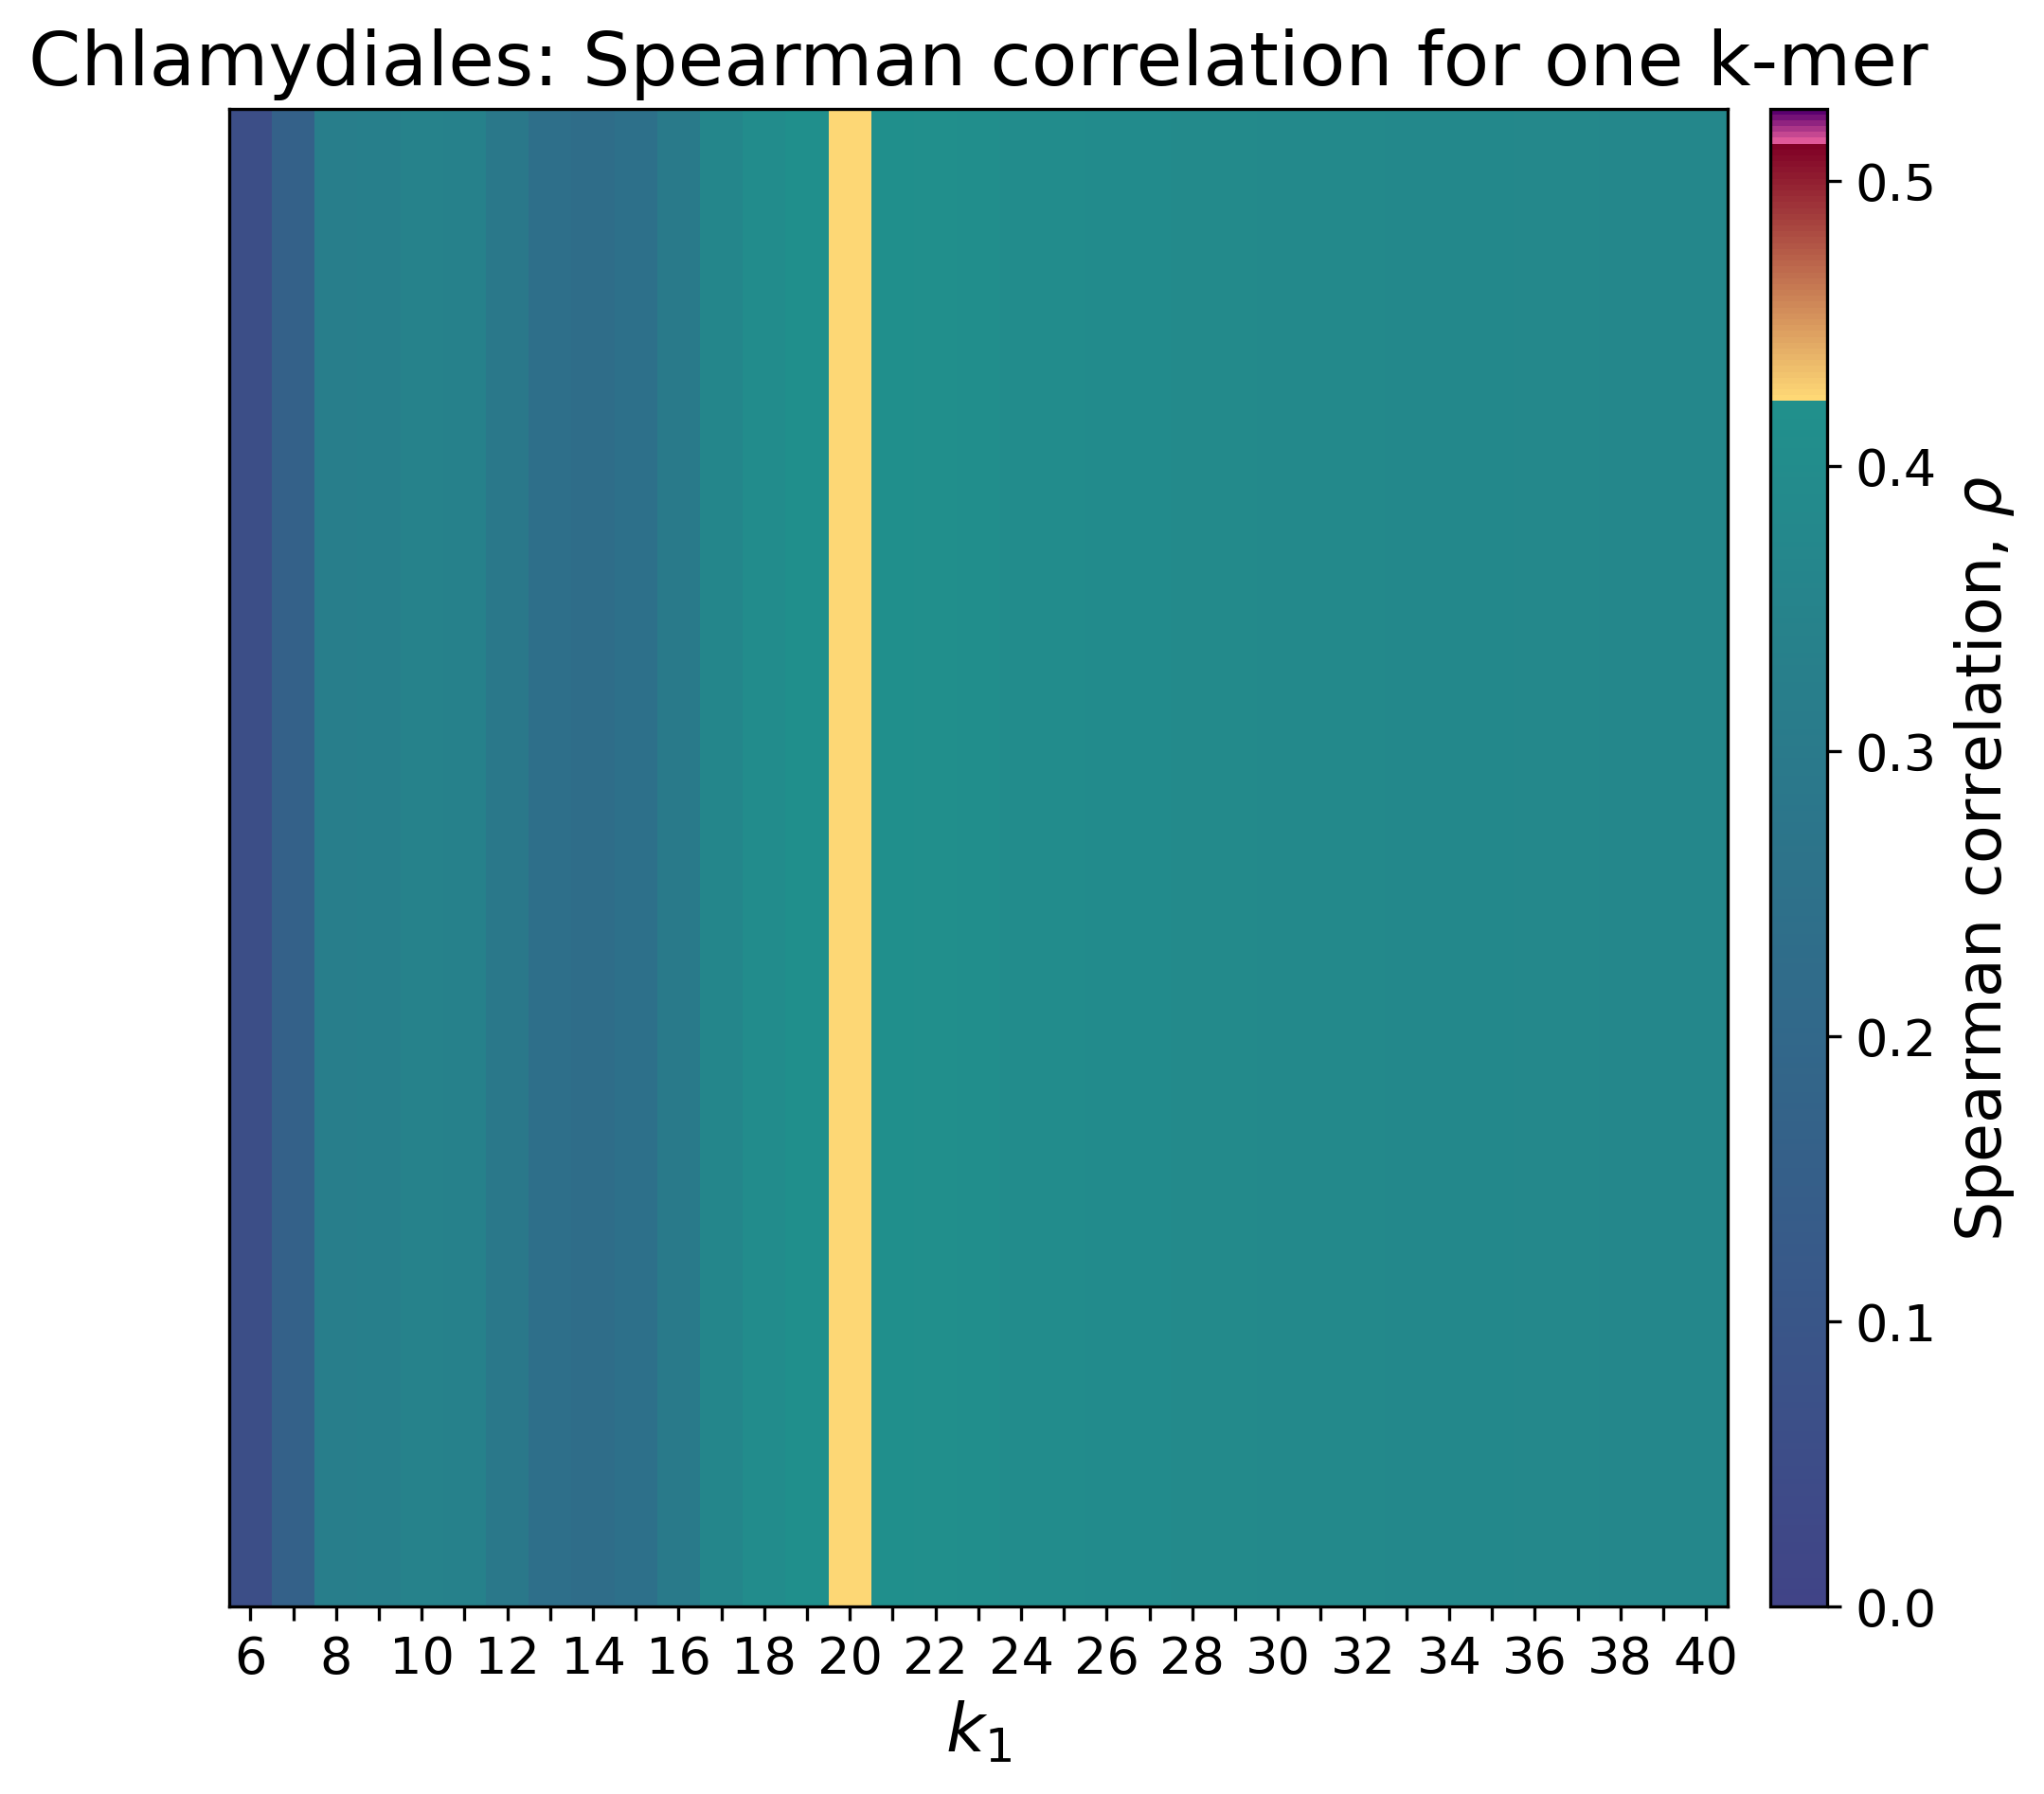

In [14]:
# Run full grid search
for name, df in datasets_1k:
    if name == 'Chlamydia':
        print(name)
        ok_k_mer.plot_1k_colorbar_corr(name, df, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        print()


### Two k-mers


Chlamydia


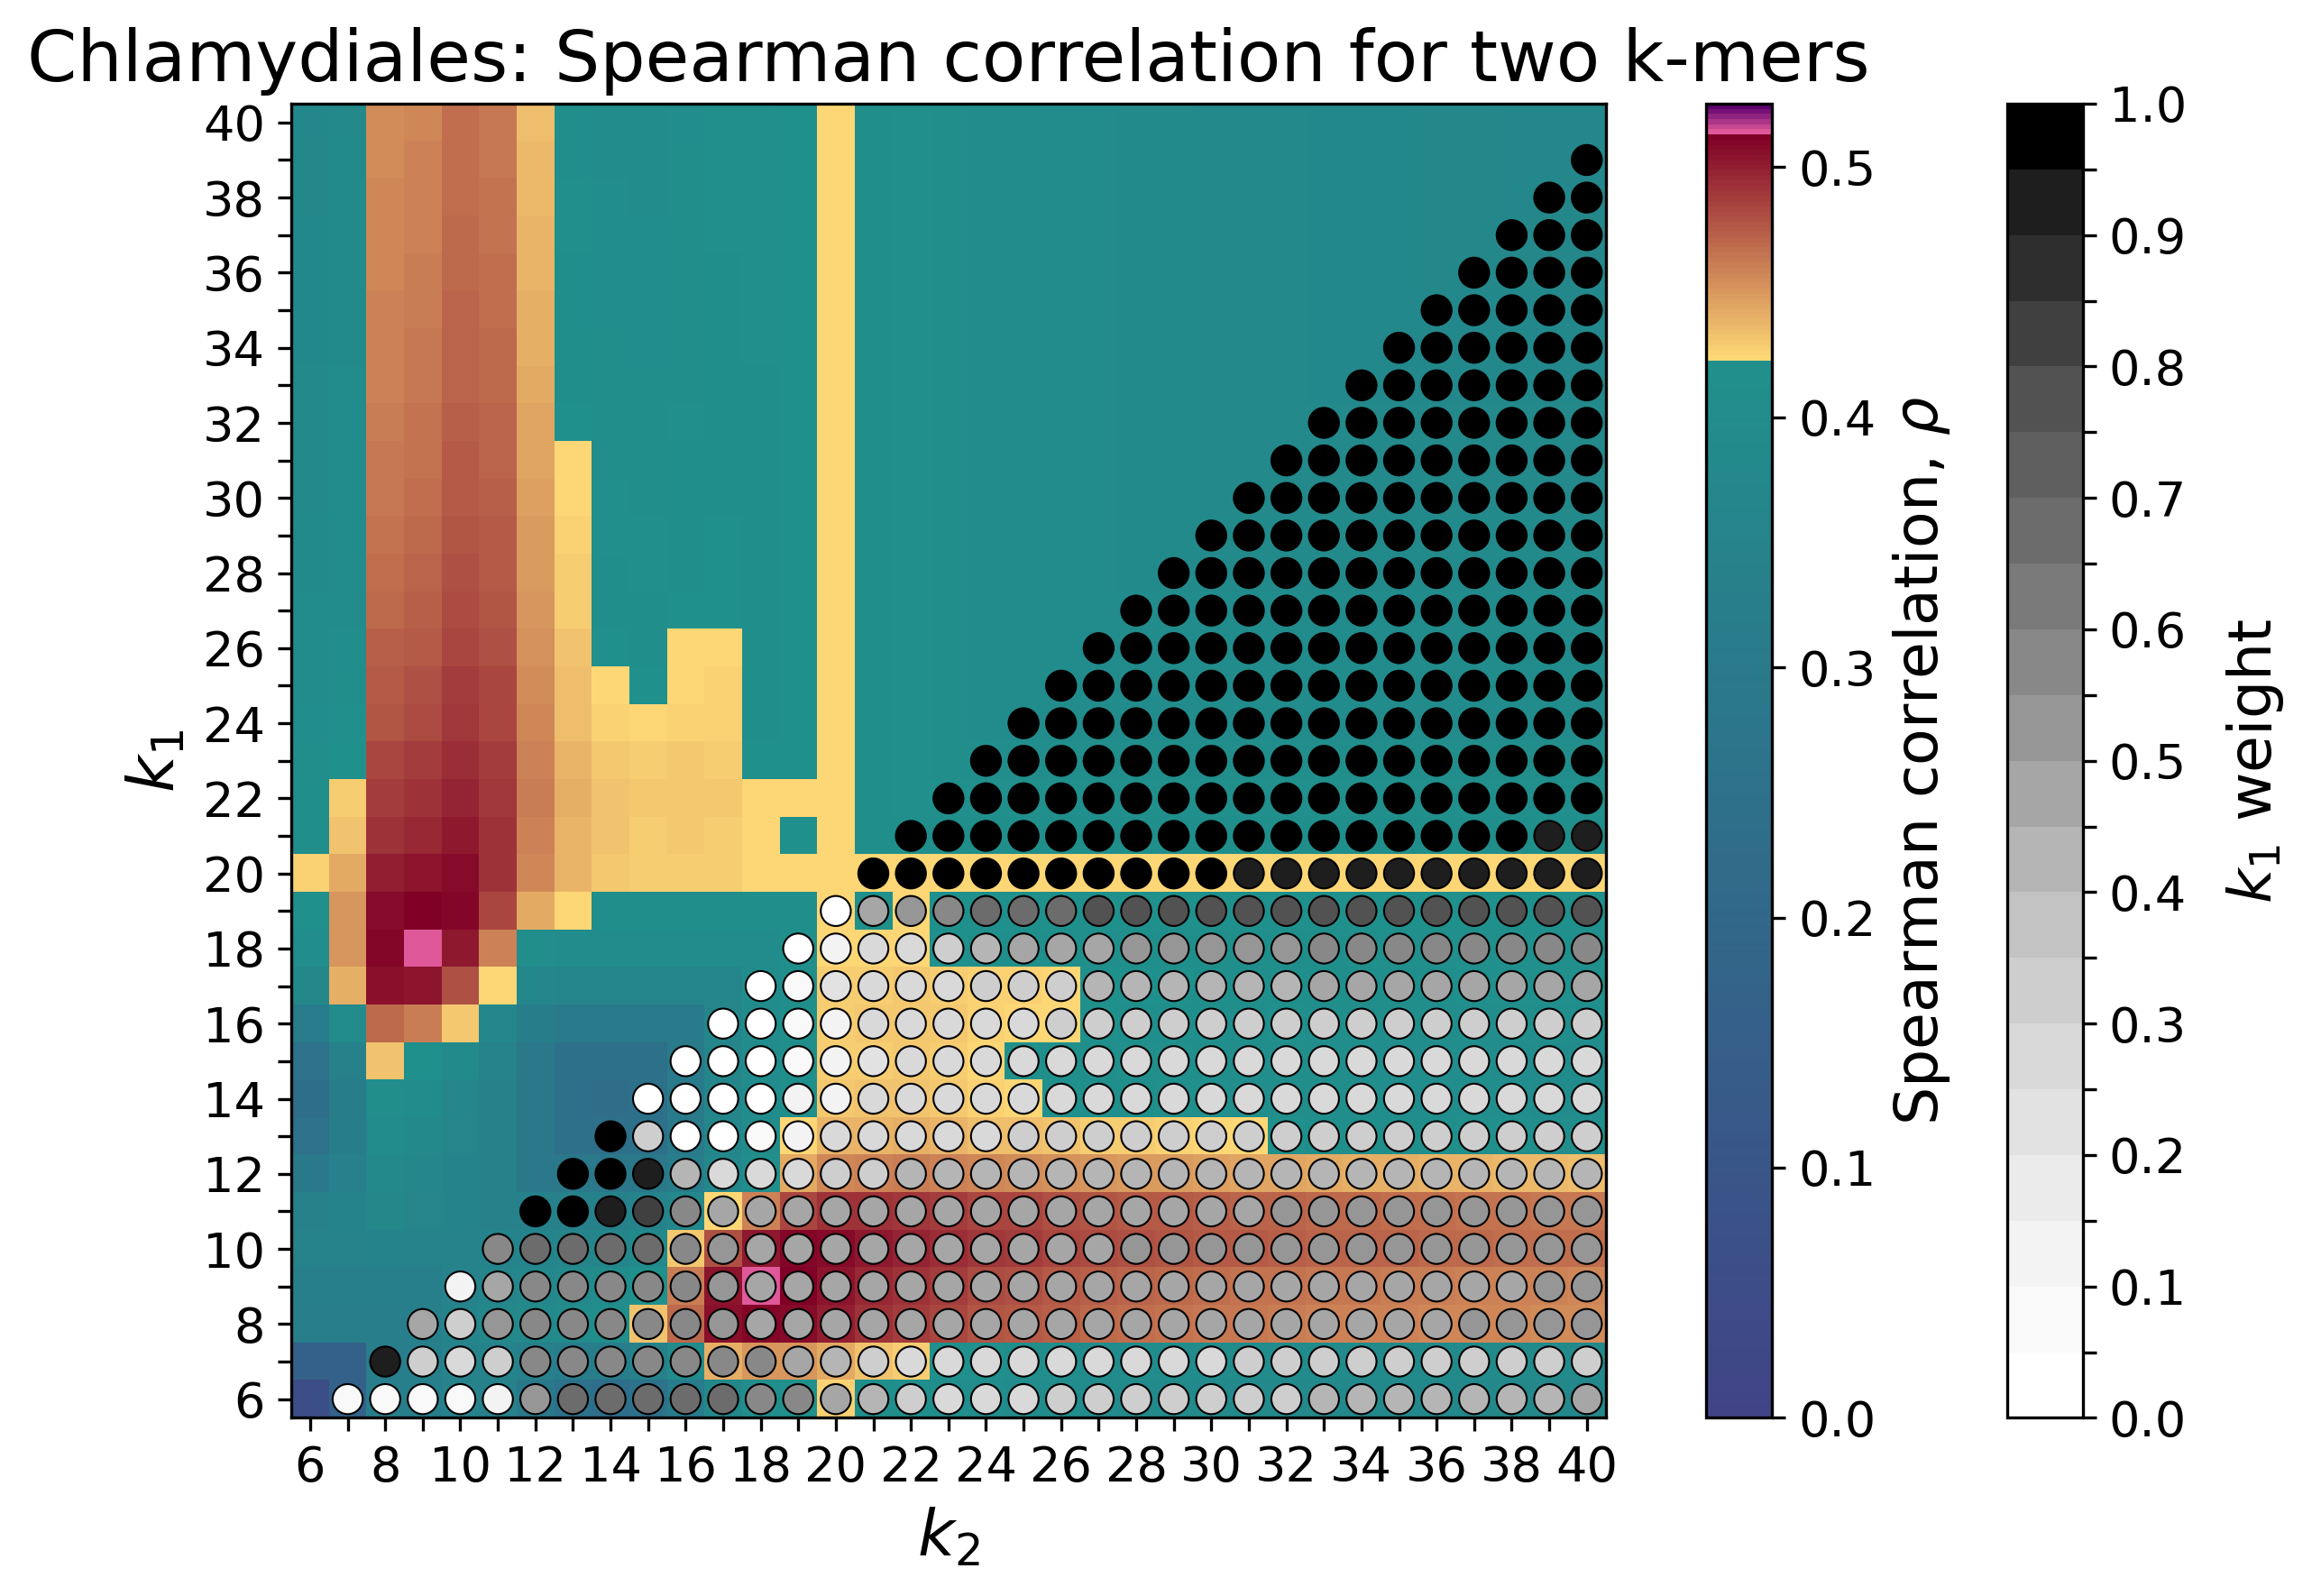

In [15]:
# Run full grid search
for name, results_matrix in datasets_2k:
    if name == 'Chlamydia':
        print(name)
        results_matrix = np.abs(results_matrix)
        # results_matrix, min_val, k1_min, k2_min, w_min, min_val = ok_k_mer.run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)   # run grid search, now is a slurm script
        ok_k_mer.plot_2k_grid_joint_corr_weight(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        # ok_k_mer.plot_2k_grid_corr(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        # ok_k_mer.plot_2k_grid_weights(name, results_matrix, k_low=6, k_high=40, w_low=0, w_high=1, w_step=0.05)
        print()


### Three k-mers

Chlamydia 20


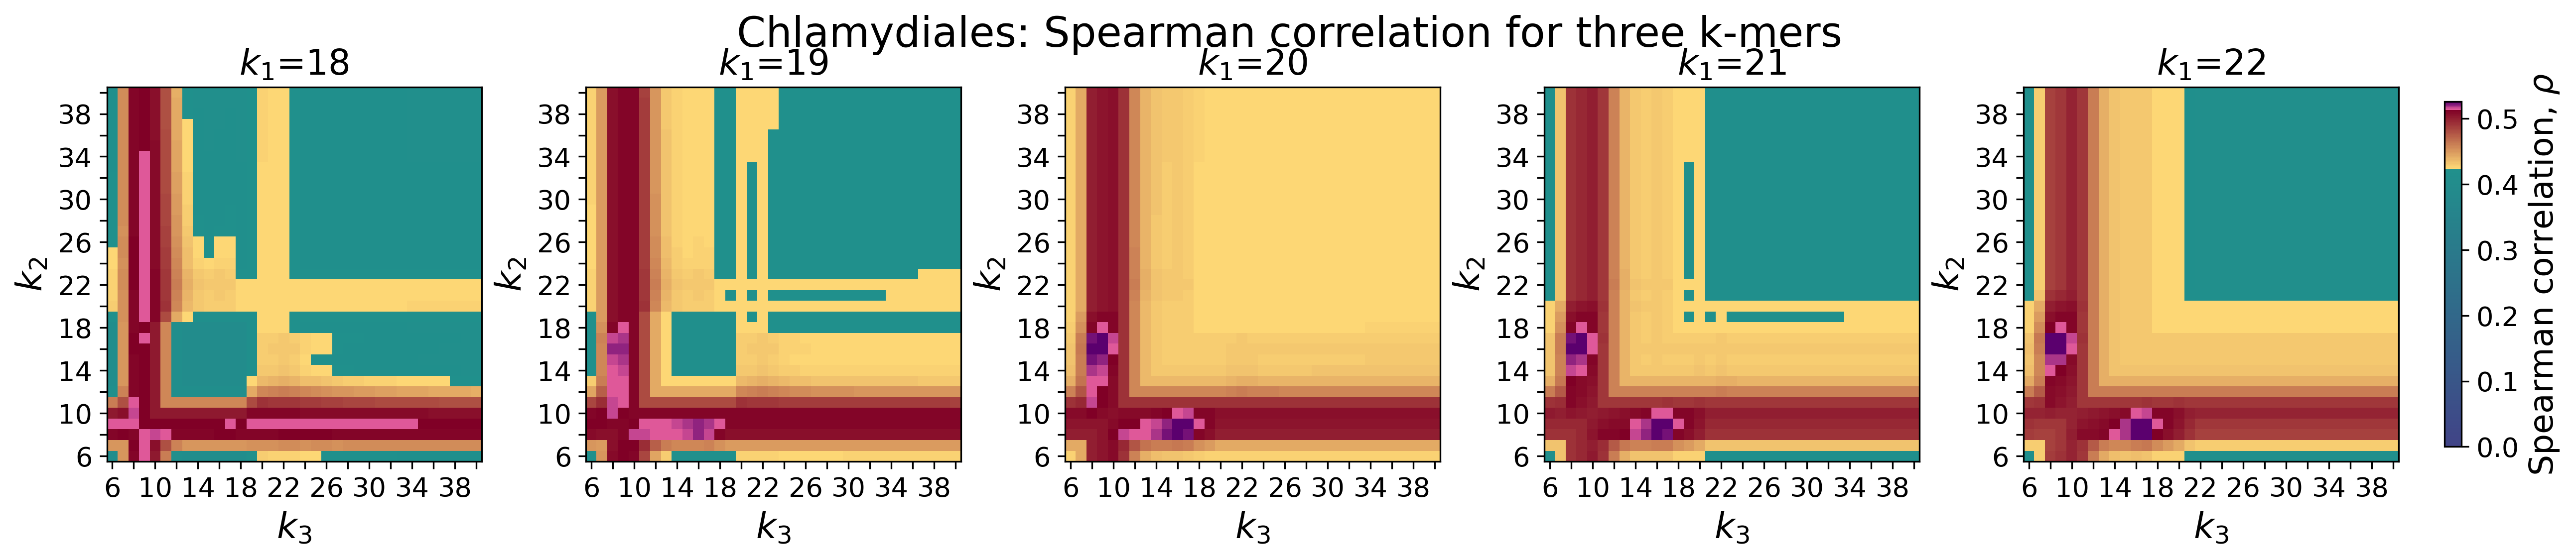

In [16]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_3k:
    if name == 'Chlamydia':
        print(name, k_best)
        results = ok_k_mer.plot_3k_grid_corr(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name])
        # results_grid_corr = ok_k_mer.plot_3k_grid_joint_corr_weight(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name], w_low=0, w_high=1, w_step=0.10)
        print()


# Fig 3: Annotated tree with k-mer pie chart

In [17]:
from ete3 import Tree, TreeStyle, TextFace, NodeStyle, faces
import ok_k_mer_tree_mask as tm
importlib.reload(tm)


<module 'ok_k_mer_tree_mask' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer_tree_mask.py'>

In [18]:
# Paths to the Newick trees for each dataset (same order as merged_df_datasets)
tree_datasets = [
    ("Aquificota",    "/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk"),
    ("Bacillales",    "/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk"),
    ("Caldisericia",  "/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk"),
    ("Chlamydia",     "/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk"),
    ("Cyano",         "/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk"),
    ("Neisseriaceae", "/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk"),
]


In [19]:
figdir = "/scratch4/blangme2/sjhwang/ok_k_mer_manuscript/figures/tmp"
os.makedirs(figdir, exist_ok=True)


Aquificota


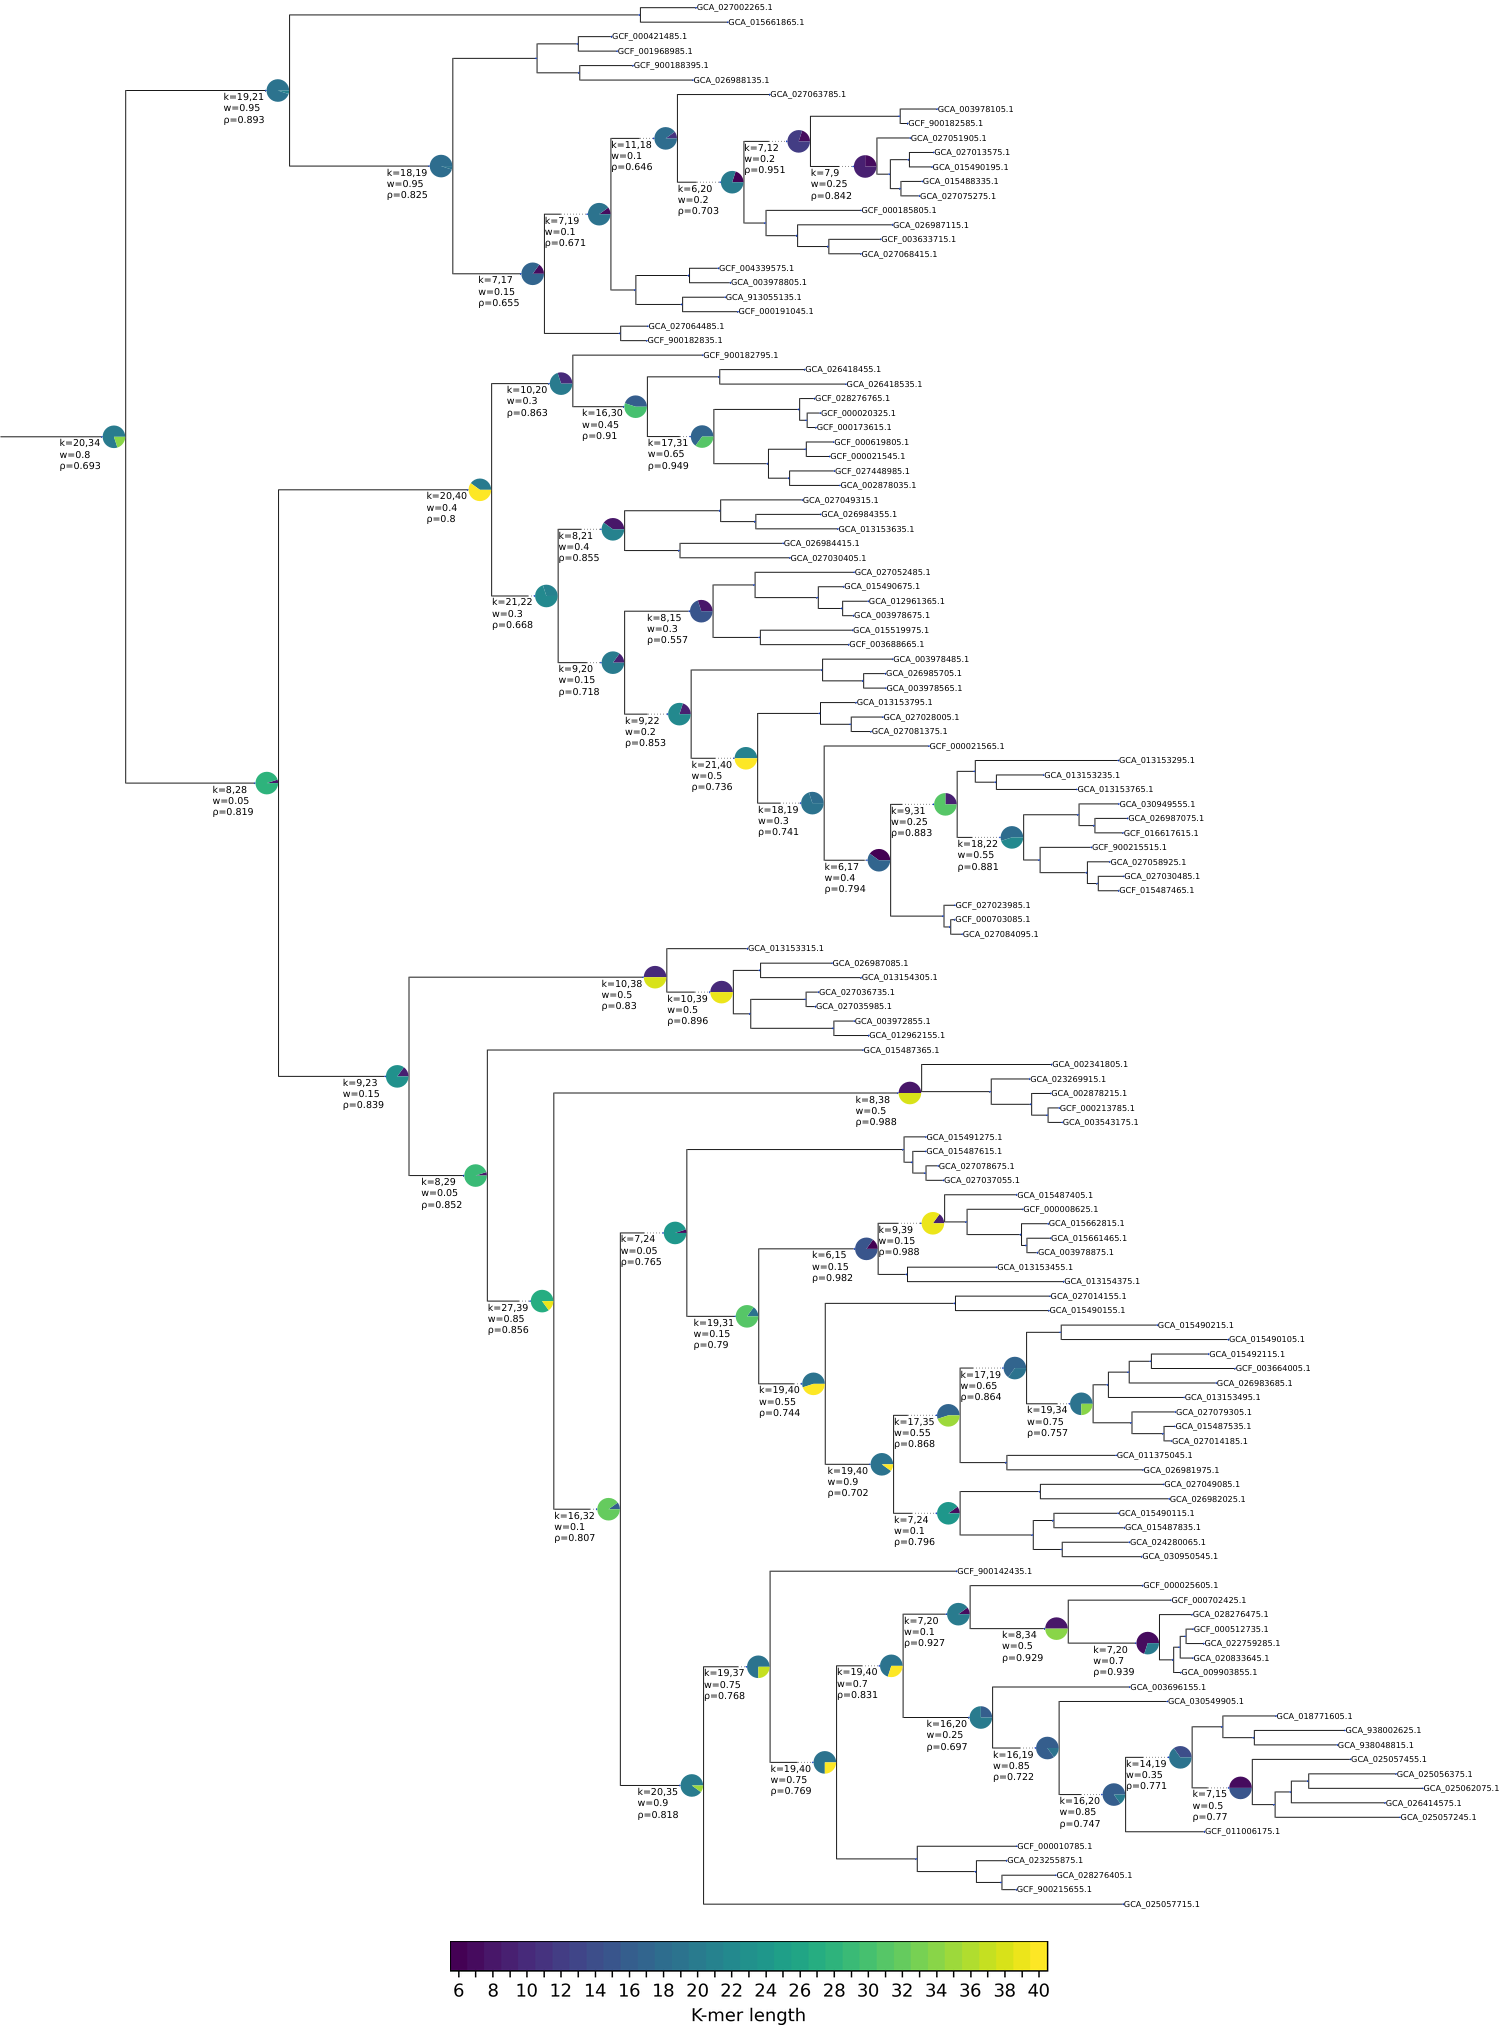


Bacillales


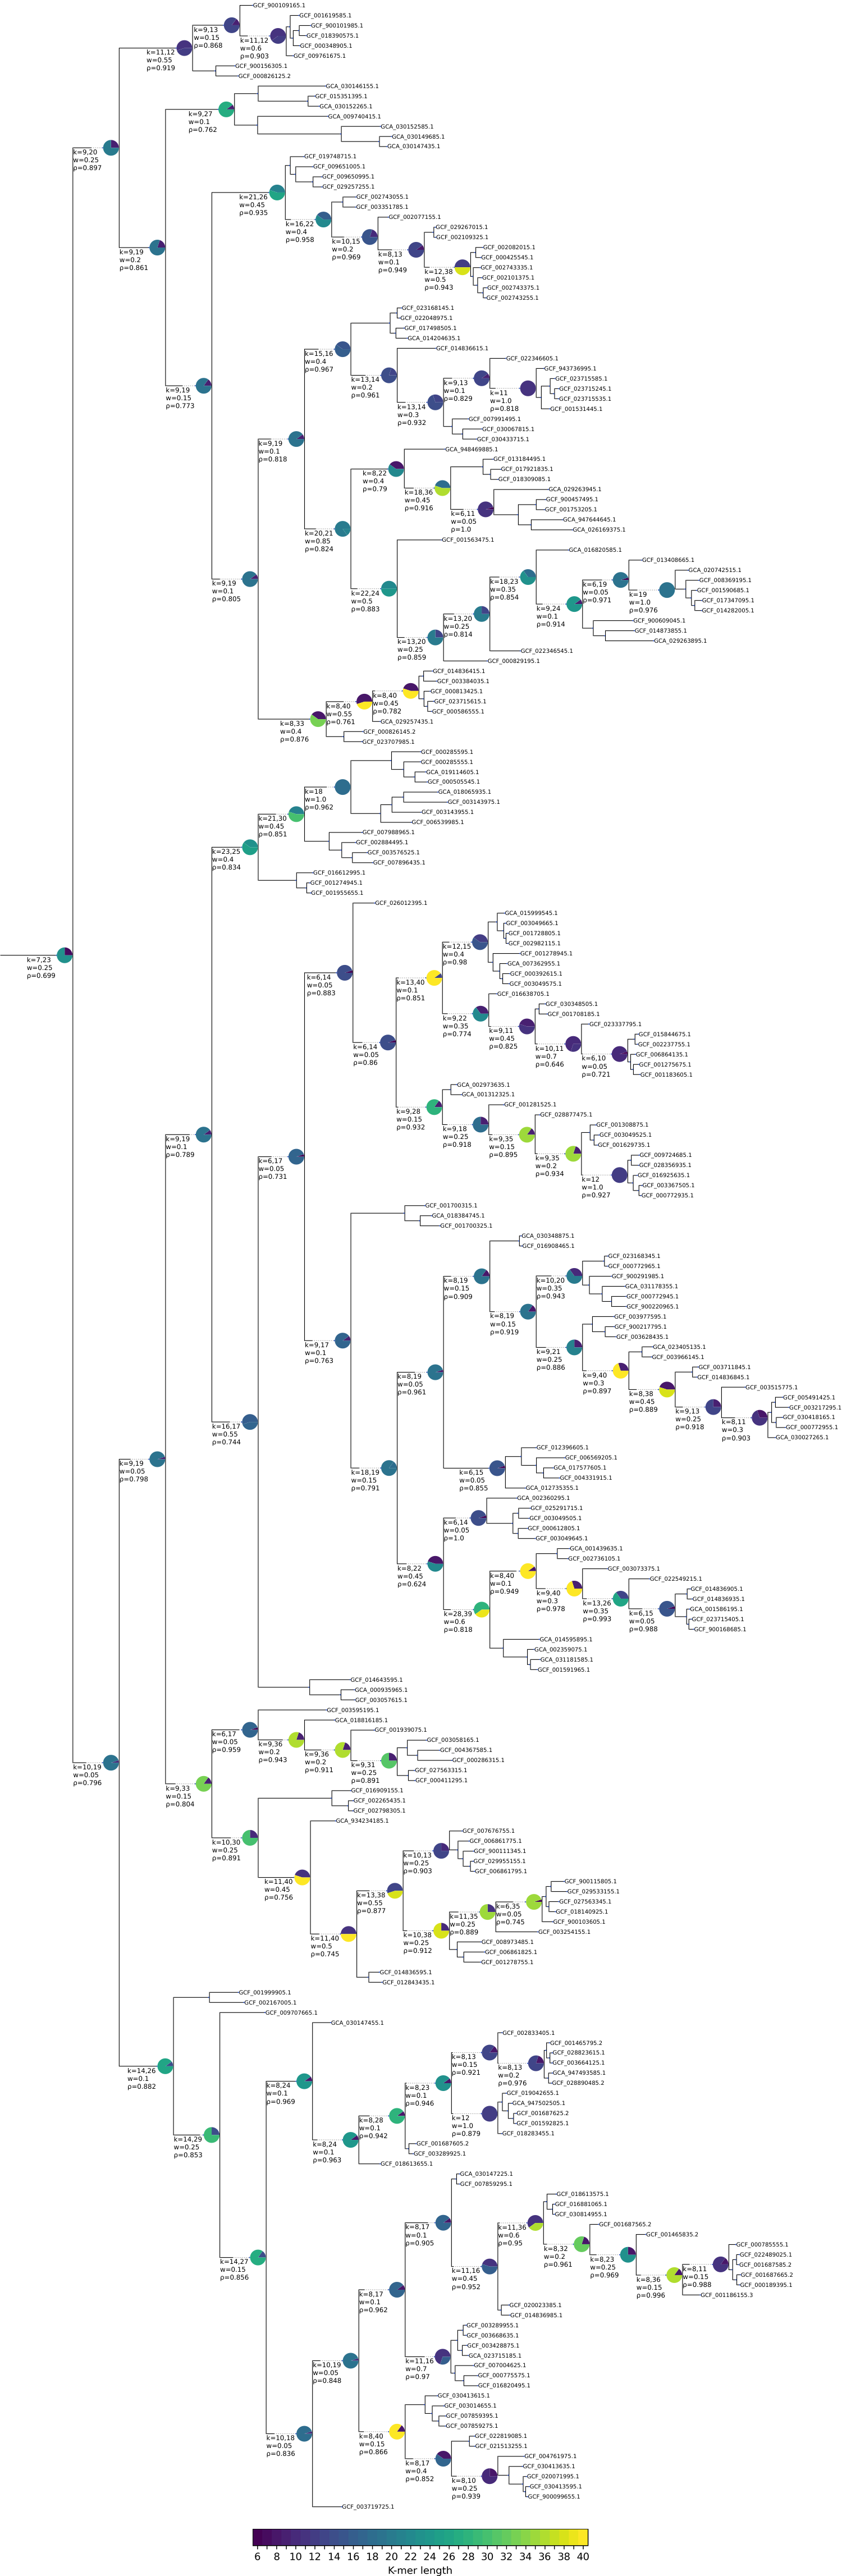


Caldisericia


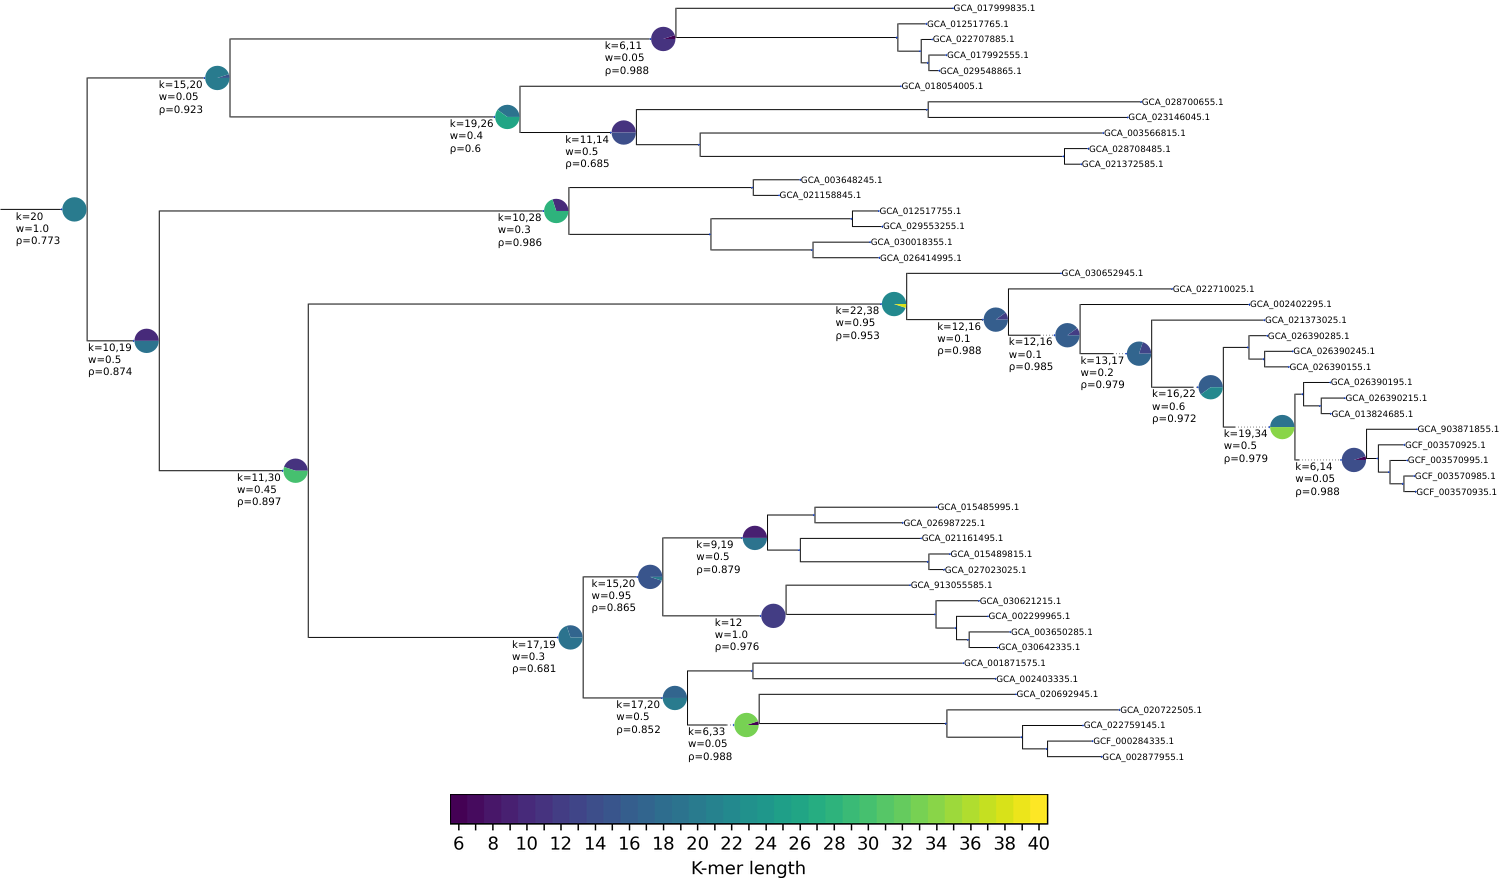


Chlamydia


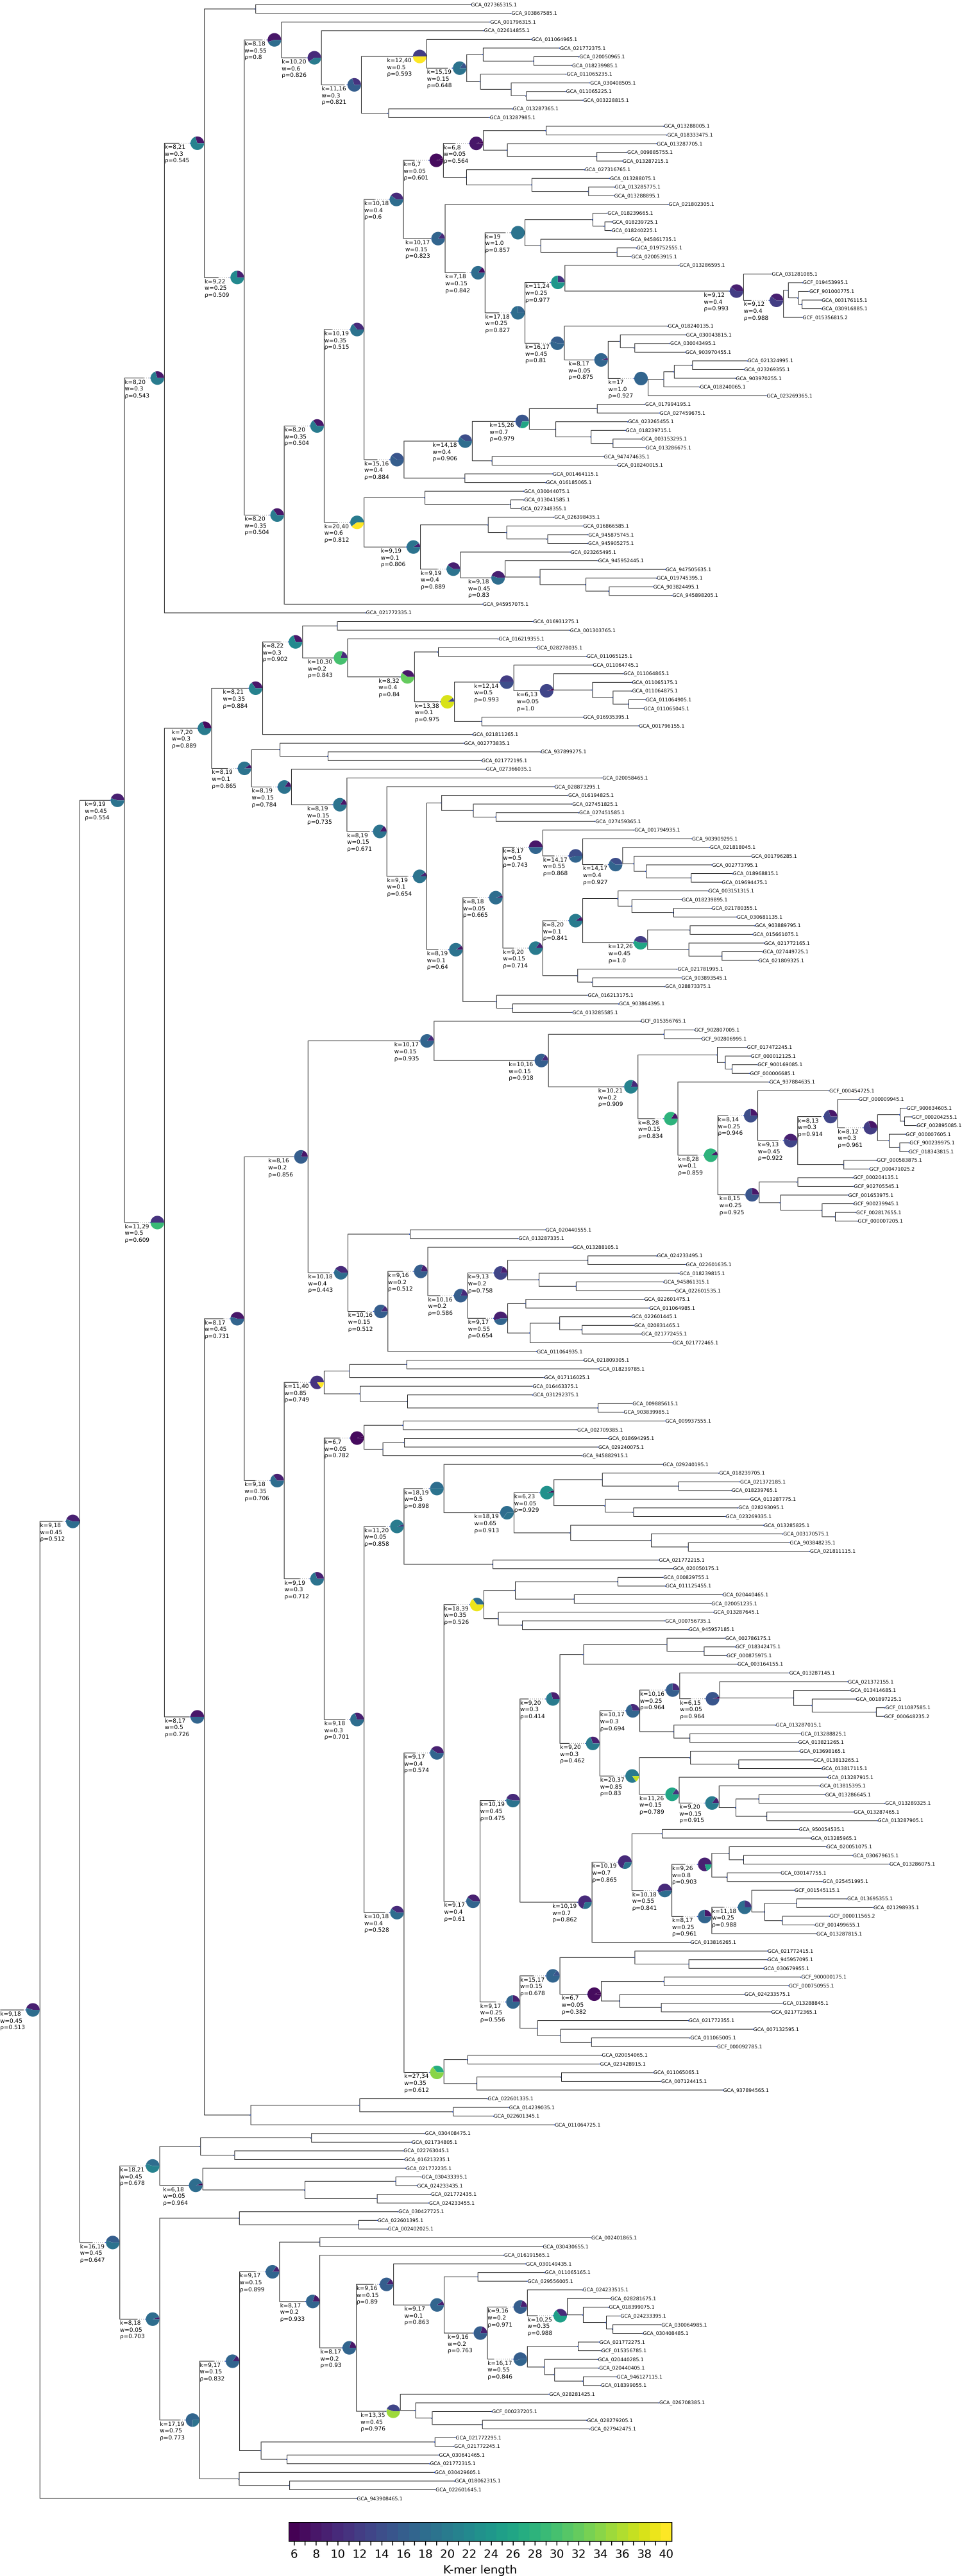


Cyano


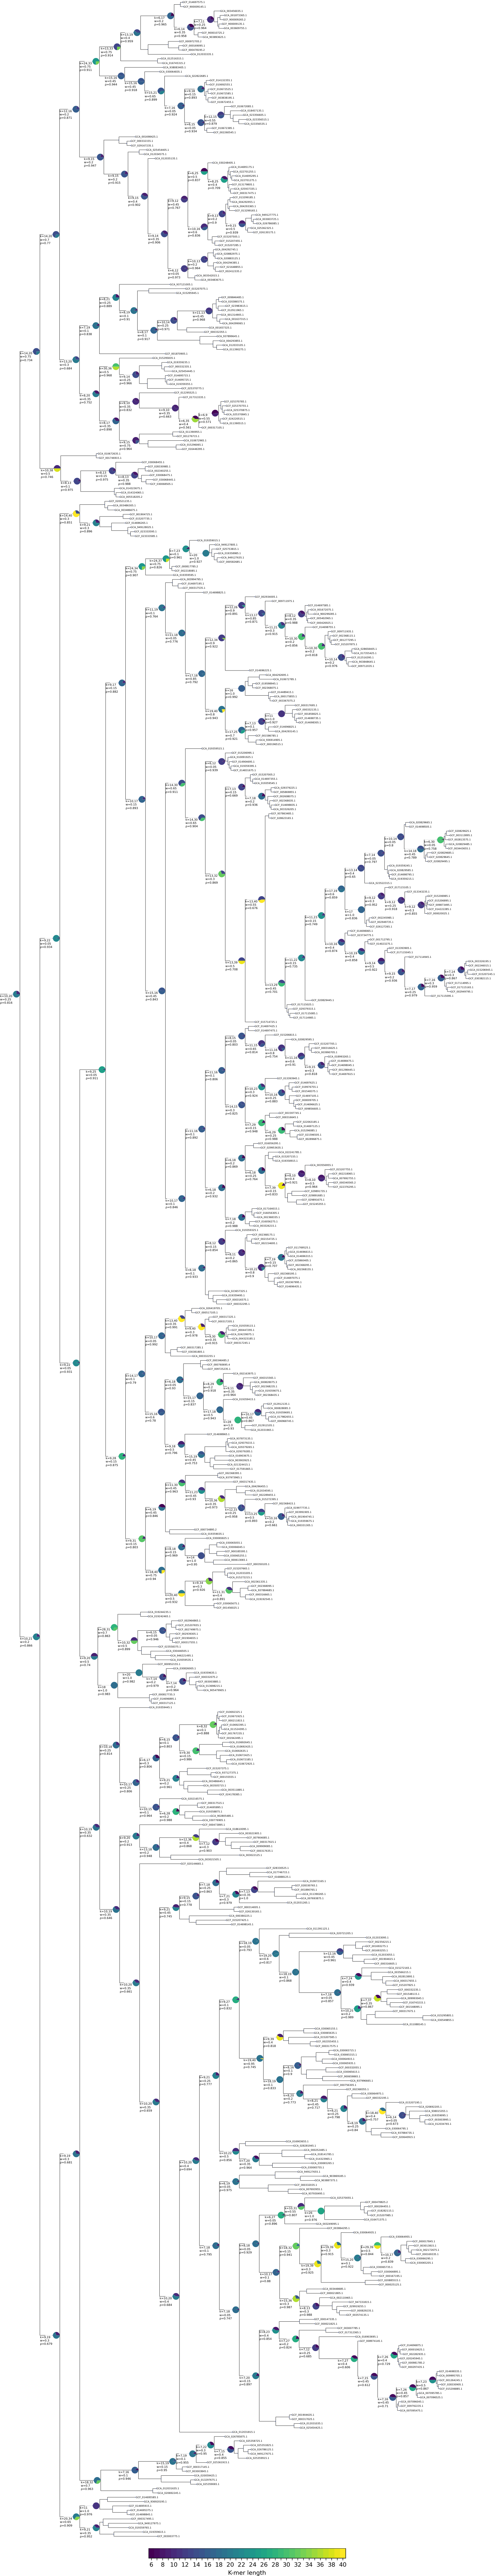


Neisseriaceae


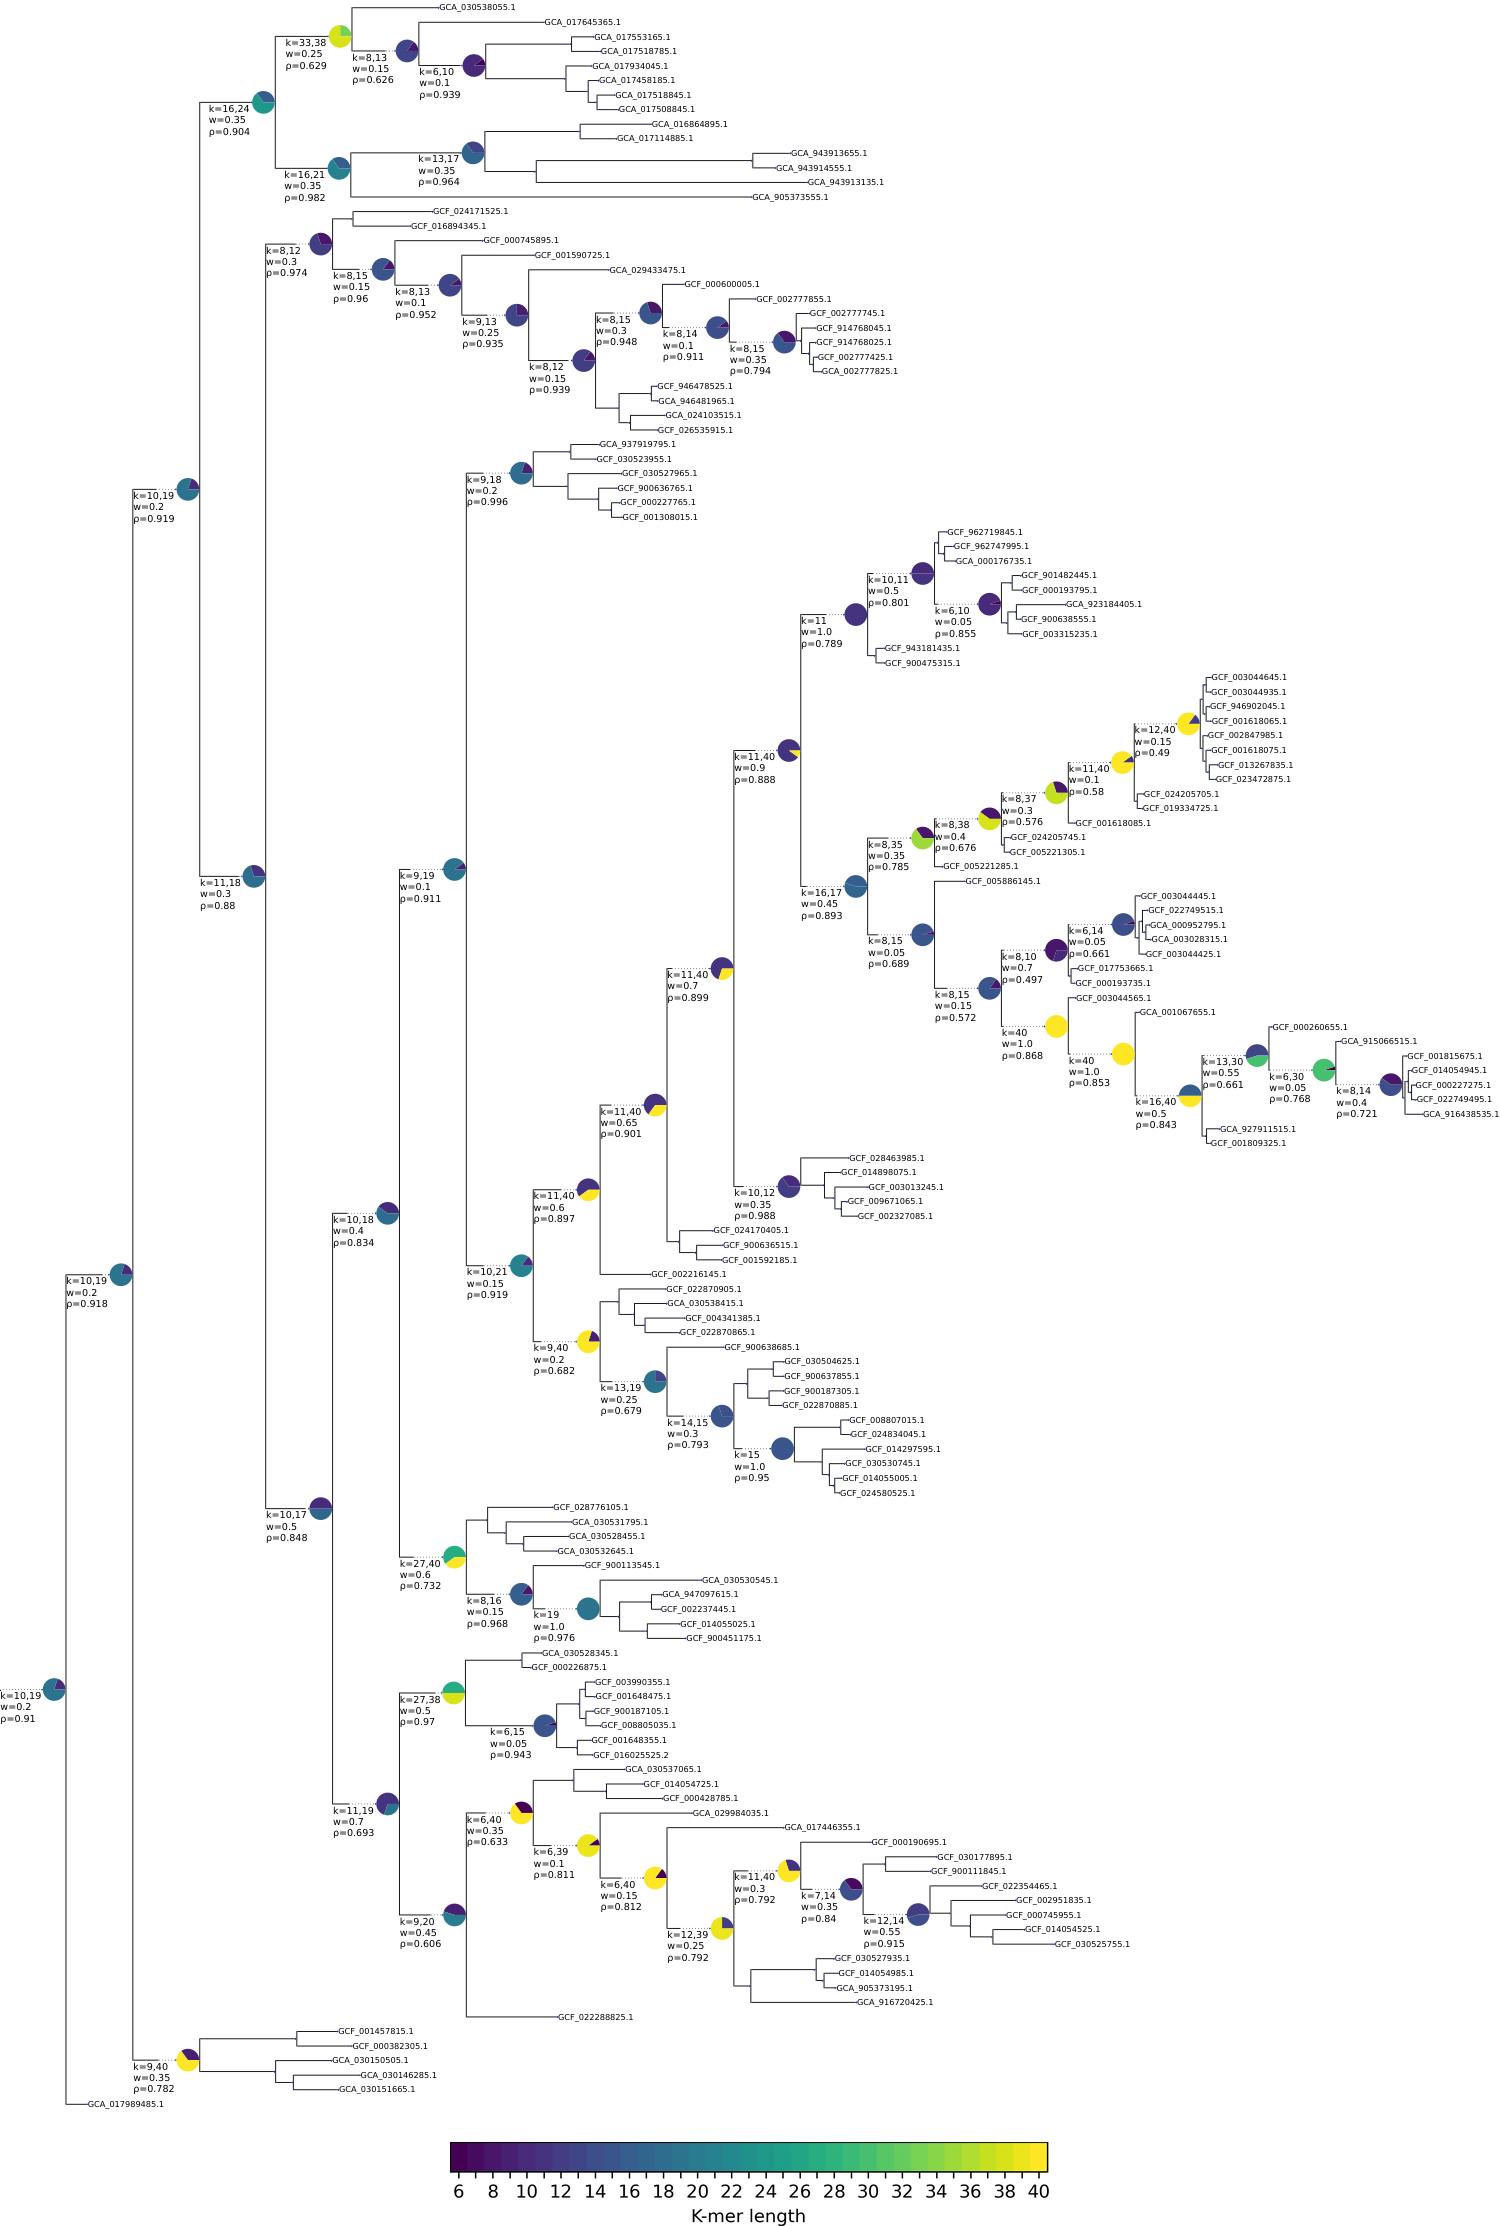

In [20]:
# Save annotated tree as PDF and 600dpi PNG

re_run = False # True

for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)

    if re_run: # re-run and save the node annotations
        node_info = tm.compute_node_annotations(tree, merged_df, k_low=6, k_high=40)
        tm.save_node_annotations(node_info, f"res/{name}_node_annotations.tsv")
    else:      # read the node annotations
        node_info = tm.read_node_annotations(f"res/{name}_node_annotations.tsv")
################################################################################
    # save the plot data
    # Vector PDF
    tm.plot_tree_annotated(tree, node_info, name=name, k_low=6, k_high=40,
                           outpath=f"{figdir}/{name}_tree_annotated.pdf",
                           display=False)
    # 600 dpi archival PNG
    tm.plot_tree_annotated(tree, node_info, name=name, k_low=6, k_high=40,
                           outpath=f"{figdir}/{name}_tree_annotated_600dpi.png",
                           dpi=600)
    print()


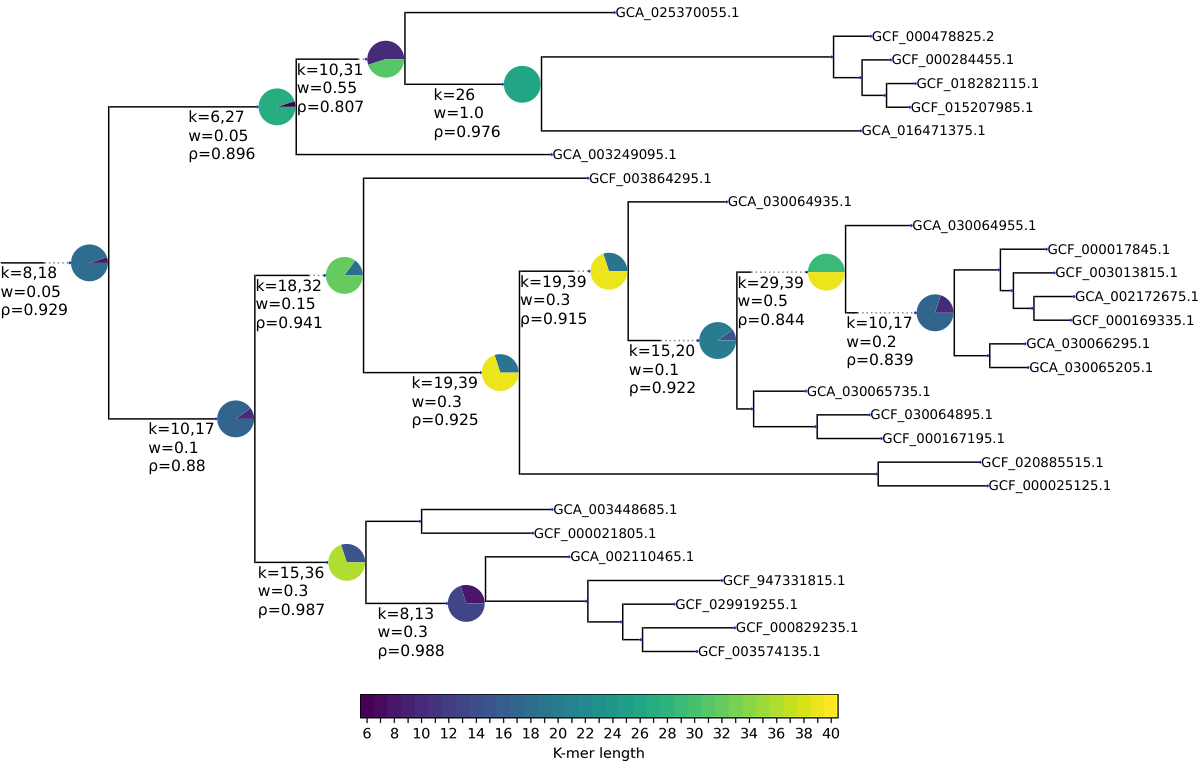

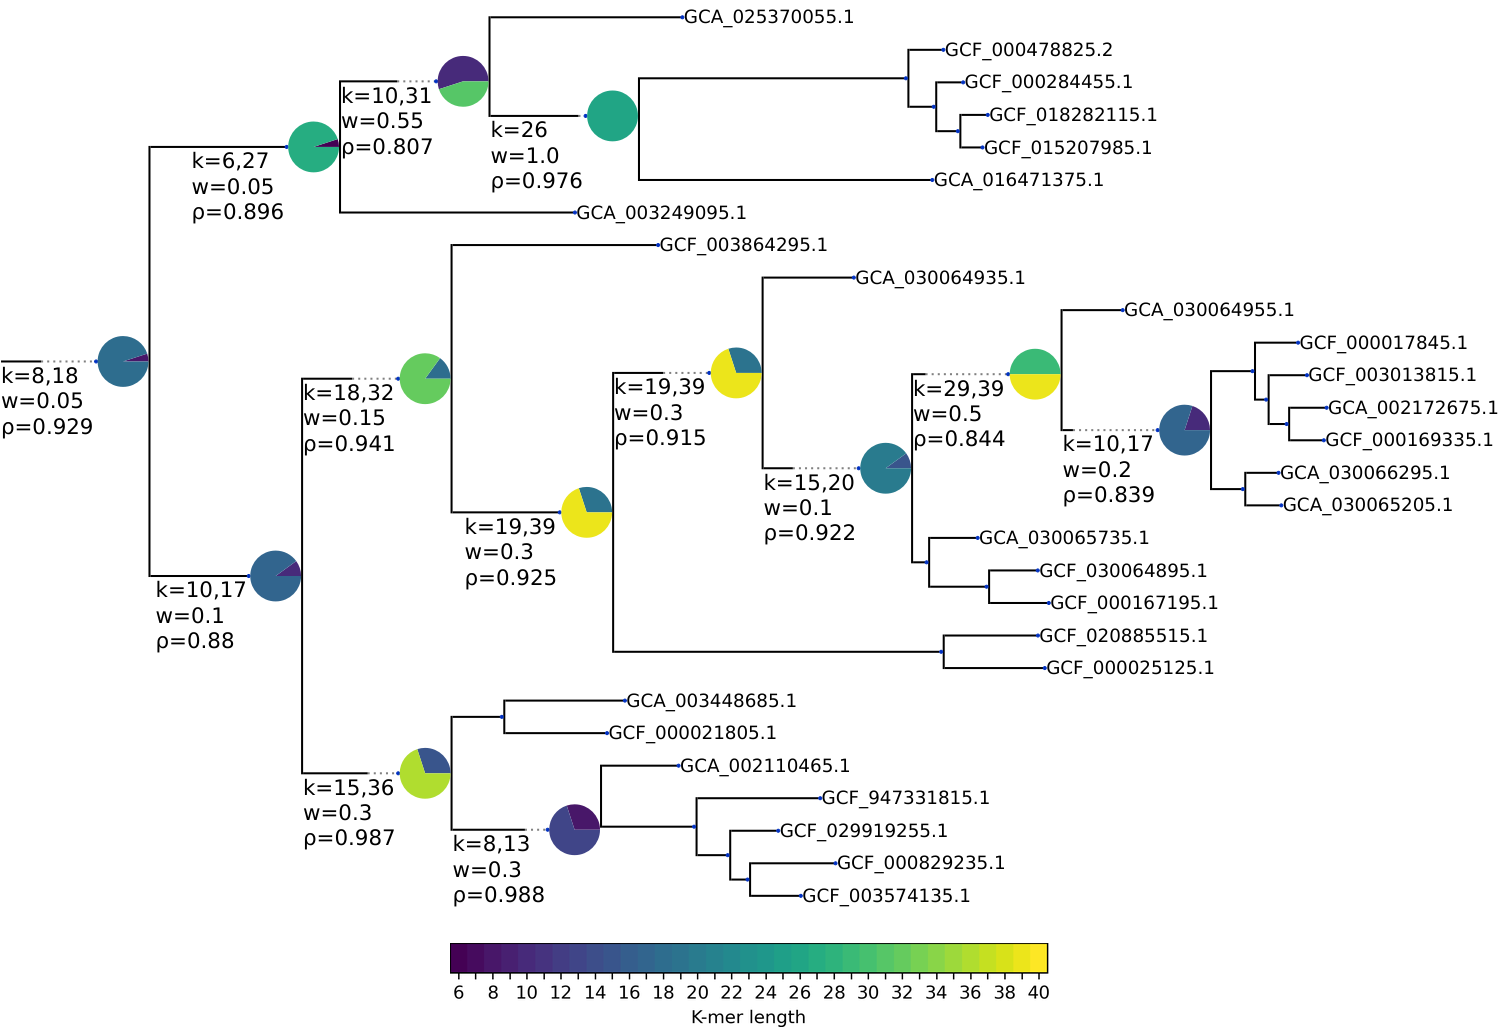

'/scratch4/blangme2/sjhwang/ok_k_mer_manuscript/figures/tmp/Cyano_subtree_annotated.png'

In [21]:
## Plot cyano subtree for slides
#   - Cyano subtree: root k=7,18 w=0.05 corr=0.747 and descendants
# cyano_tree = tm.load_named_tree(tree_datasets[4][1])
# cyano_mdf = merged_df_datasets[4][1]
# cyano_node_info = tm.compute_node_annotations(
#     cyano_tree, cyano_mdf, k_low=6, k_high=40, w_step=0.05)
# cyano_subtree_root = tm.find_node_by_annotation(
#     cyano_node_info, k1=8, k2=18, w=0.05, corr=0.929)

cyano_tree_path = "/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk"
cyano_tree = tm.load_named_tree(cyano_tree_path)
cyano_node_info = tm.read_node_annotations(f"res/Cyano_node_annotations.tsv")

tm.plot_tree_annotated(
    cyano_tree, cyano_node_info, name='Cyano',
    node_id='internal_node_351',
    outpath='res/Cyano_subtree_node299_annotated.png', width=1200, scale=3000)

# Vector PDF
tm.plot_tree_annotated(
    cyano_tree, cyano_node_info, name='Cyano', k_low=6, k_high=40,
    node_id='internal_node_351',
    outpath=f"{figdir}/Cyano_subtree_annotated.pdf",
    display=False)

# 600 dpi archival PNG
tm.plot_tree_annotated(
    cyano_tree, cyano_node_info, name='Cyano', k_low=6, k_high=40,
    node_id='internal_node_351',
    outpath=f"{figdir}/Cyano_subtree_annotated.png",
    dpi=600)

# Fig 4: Global consistency vs masking fraction

Does masking x% of the genomes still yield a robust whole-tree k-mer
recommendation? For each fraction we mask several random subsets and
recompute the recommendation on the rest, comparing to the full-data
recommendation via four scores (mean +/- 1 std over runs):

- **match rate**: fraction of runs whose `k_eff` is within +/-1 k of full.
- **mean |dk_eff|**: average absolute deviation of `k_eff` from full.
- **correlation retention**: `|corr_masked| / |corr_full|`.
- **genome-pair ordering**: normalized Kendall-tau distance between the
  full and masked recommendations' pair orderings, plus the degradation of
  the masked ordering relative to the tree-distance truth.

In [22]:
import ok_k_mer_tree_mask as tm
importlib.reload(tm)


<module 'ok_k_mer_tree_mask' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer_tree_mask.py'>

Aquificota: 120 runs, 15 at 0% masking
Bacillales: 120 runs, 15 at 0% masking
Caldisericia: 120 runs, 15 at 0% masking
Chlamydia: 120 runs, 15 at 0% masking
Cyano: 120 runs, 15 at 0% masking
Neisseriaceae: 120 runs, 15 at 0% masking


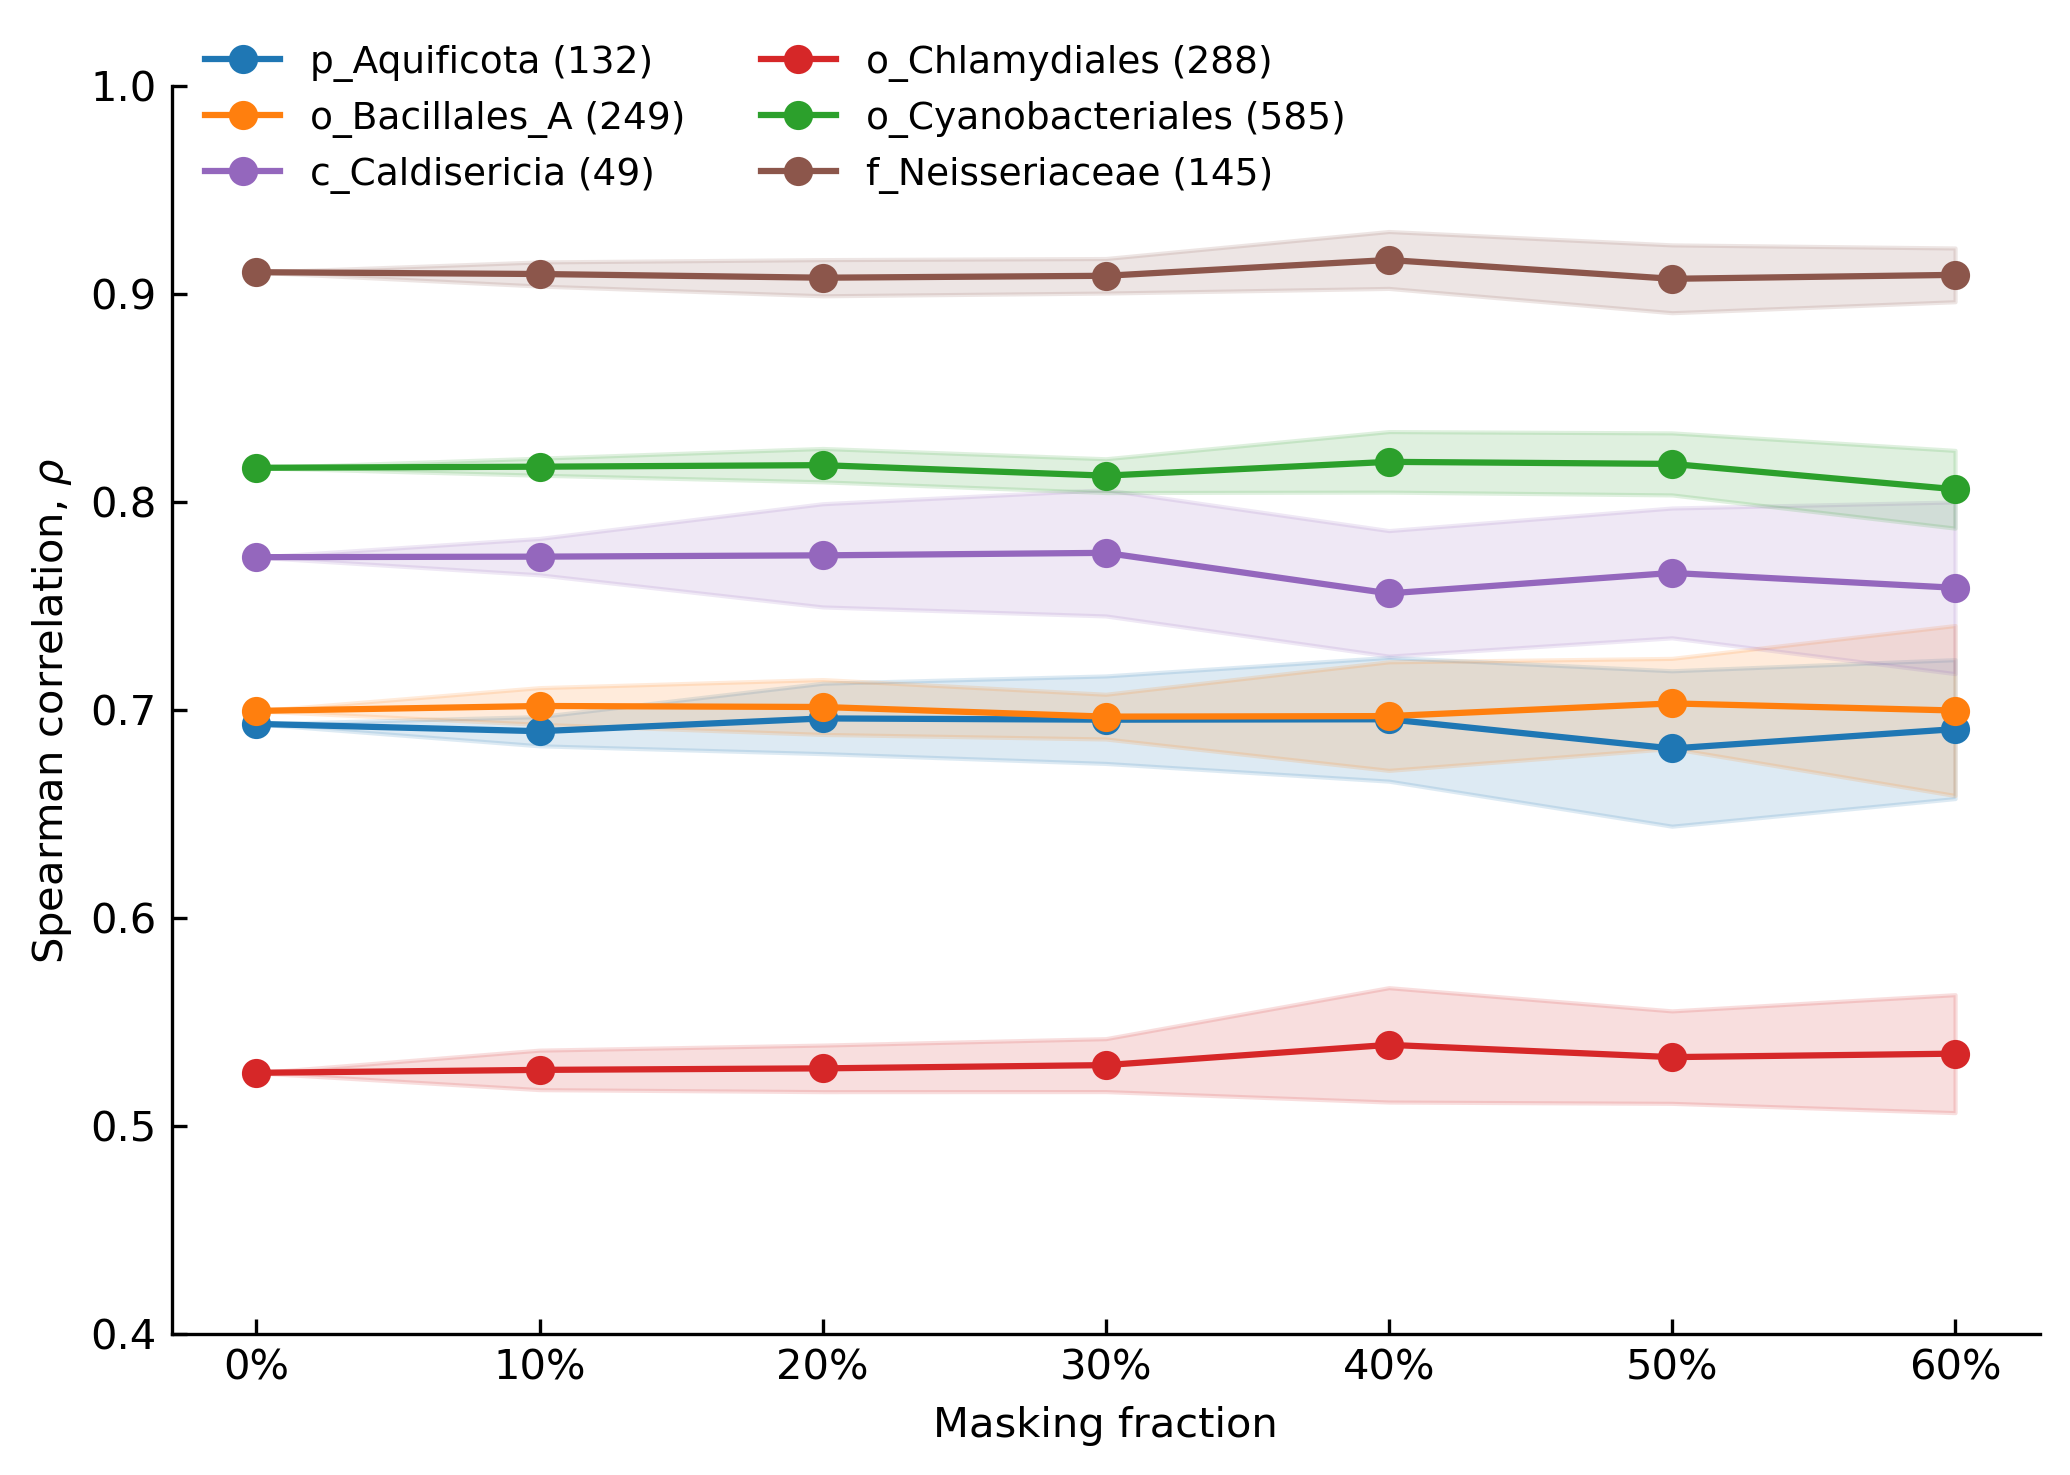

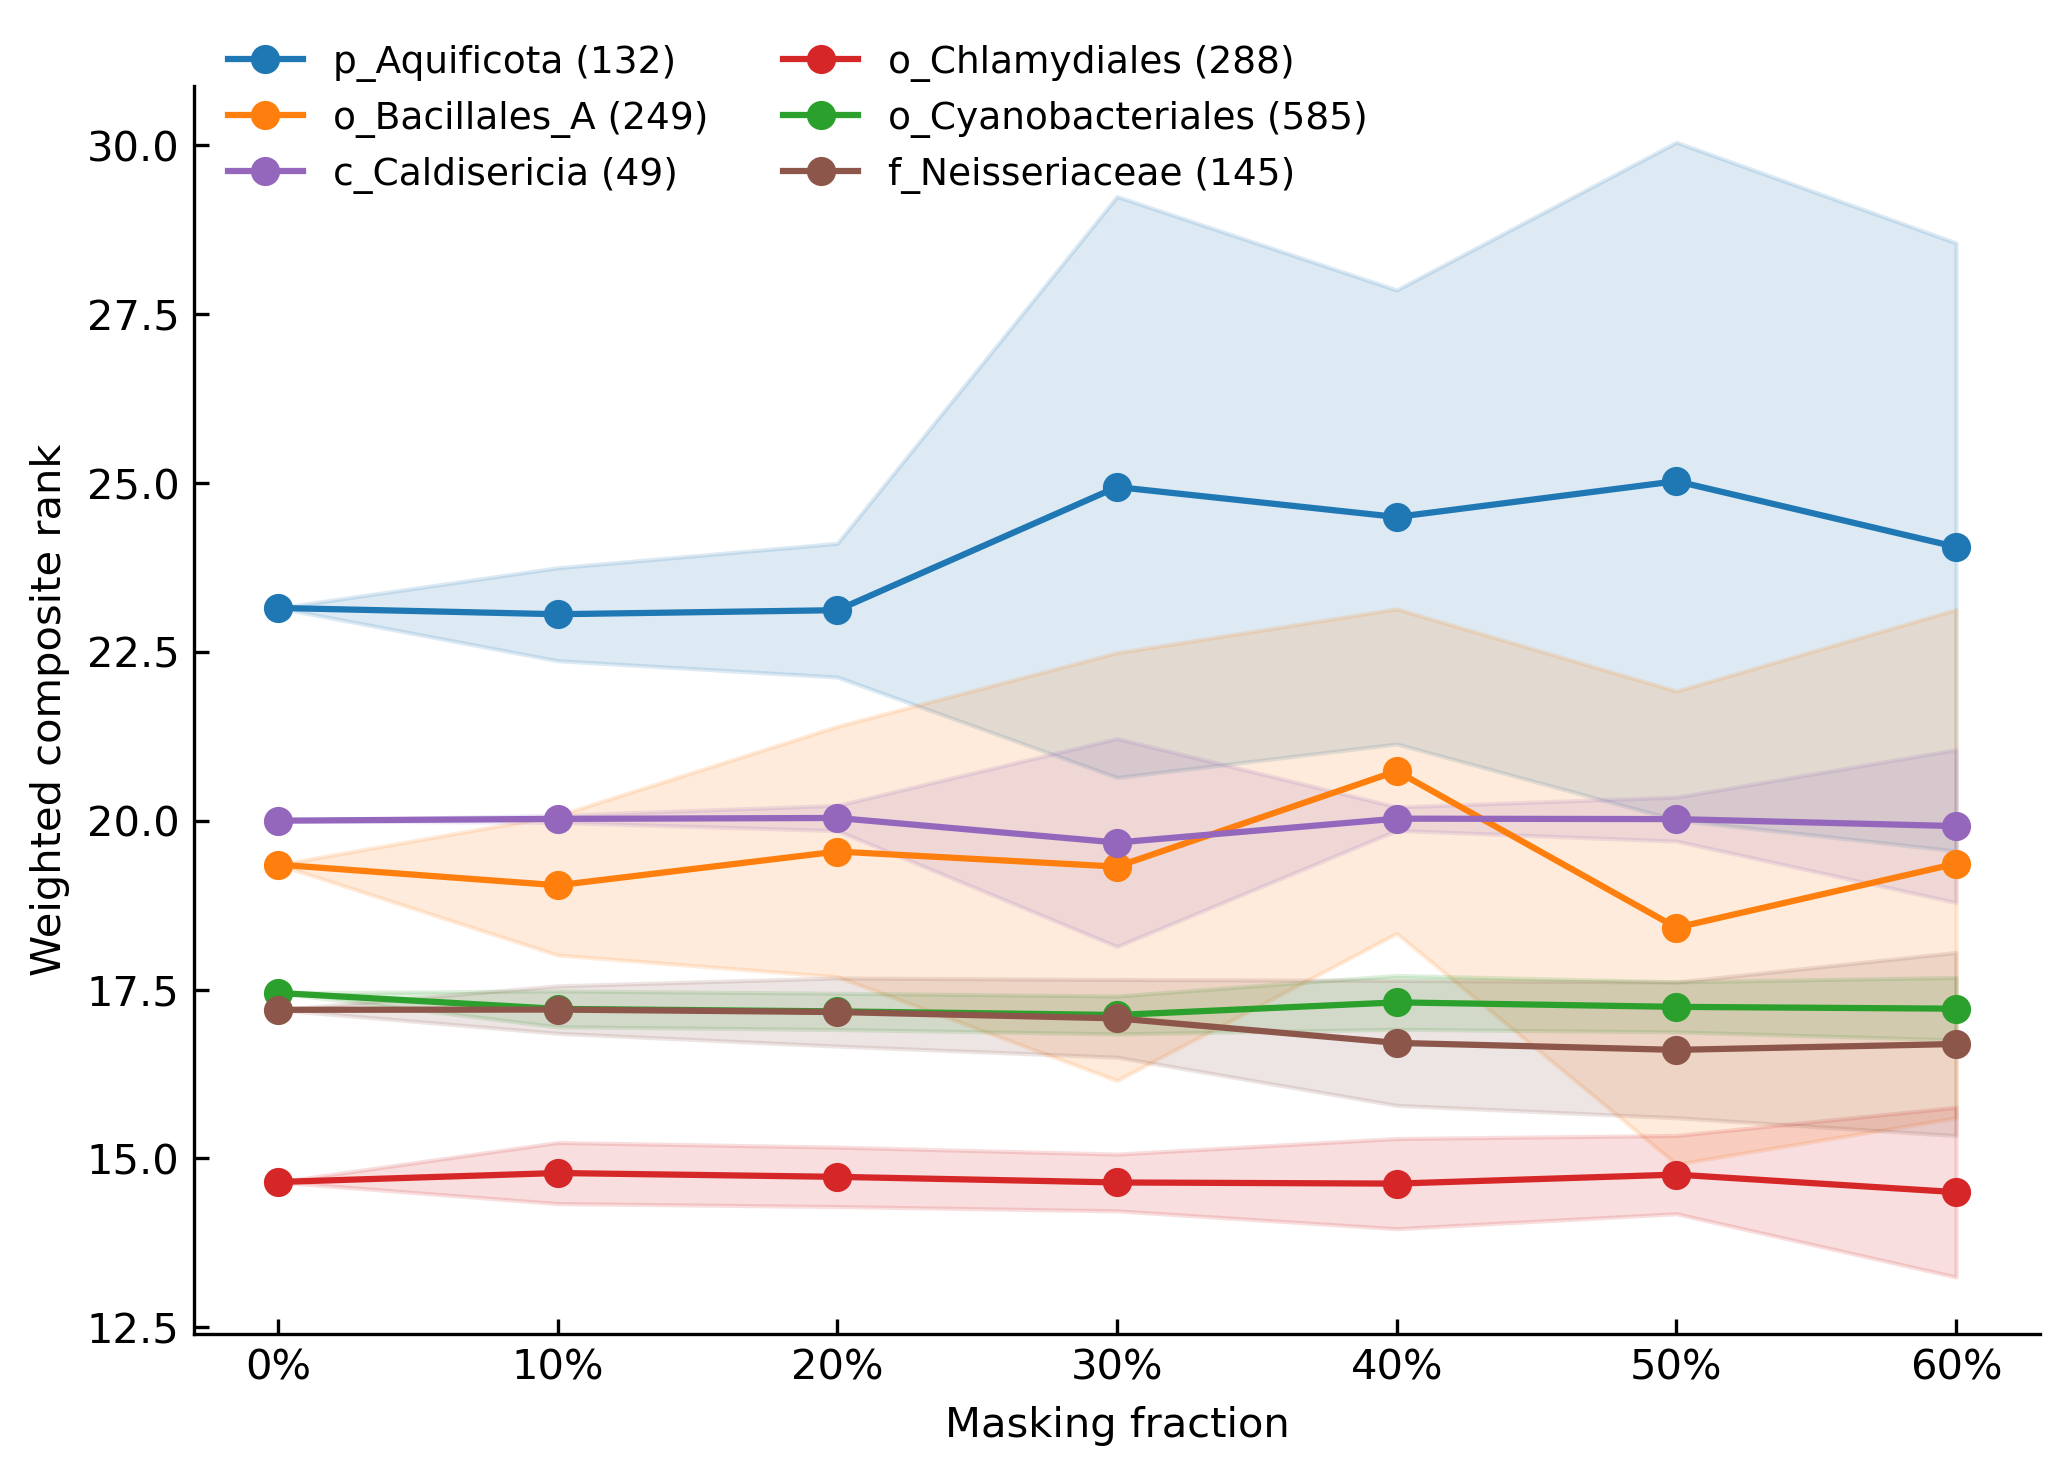

In [23]:
# load in and make 3 k-mer stability plots

sim_path = "/vast/blangme2/sjhwang/ok_k_mer_data/stability_3k/stability_simulations.csv"
sim = pd.read_csv(sim_path)

# One unmasked run (0% masking) is stored per dataset, along with 15 runs
# at each fraction from 10% through 70%. Repeat that unmasked result so
# 0% also has 15 identical simulations: the mean is unchanged, the
# standard deviation is 0, and the band widens from 0% to 10%.
dataset_order = [name for name, _ in merged_df_datasets]
global_consistency_results = {}
for name in dataset_order:
    sub = sim.loc[sim["dataset"] == name].copy()
    sub = sub.rename(columns={
        "masking_fraction": "frac",
        "correlation": "corr",
        "simulation": "run",
    })
    baseline = sub.loc[sub["frac"] == 0]
    if len(baseline) == 1:  # hypothetical repeat of 0% masking 15X for spread increase from 0% to 10%
        copies = pd.concat([baseline] * 15, ignore_index=True)
        copies["run"] = range(15)
        sub = pd.concat([sub.loc[sub["frac"] != 0], copies], ignore_index=True)
    global_consistency_results[name] = sub
    n0 = int((sub["frac"] == 0).sum())
    print(f"{name}: {len(sub)} runs, {n0} at 0% masking")

max_frac = 0.6  # plot through the 60% masking decile; options up to 0.7
rho_plot = tm.plot_spearman_vs_masking(global_consistency_results, max_frac=max_frac)
k_mer_plot = tm.plot_effective_length_vs_masking(global_consistency_results, max_frac=max_frac)

# Note; the spread is +/-1 SD from the mean.

In [24]:
# Save Fig 4 (tree masking) for the manuscript

figdir = "/scratch4/blangme2/sjhwang/ok_k_mer_manuscript/figures/tmp"
os.makedirs(figdir, exist_ok=True)

for fig, stem in (
    (k_mer_plot, "fig4_tree_masking_3_k_mer"),
    (rho_plot, "fig4_tree_masking_3_k_mer_rho"),
):
    fig.savefig(
        f"{figdir}/{stem}.pdf",
        format="pdf",
        bbox_inches="tight",
        pad_inches=0.03,
        facecolor="white",
    )
    fig.savefig(
        f"{figdir}/{stem}.png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.03,
        facecolor="white",
    )

# Scratch